# 오토인코더 파일별 1 · 코드잇 AutoEncoder 강의

**한 줄 요약** · 강의 PDF의 '원기둥 데이터셋' 예를 코드로 만들어, 그림 1,024칸을 숫자 2개로 줄였다 되돌리는 오토인코더를 학습하고 잠재 공간 · 노이즈 제거 · 이상 탐지까지 확인

- **원본** · `7. 딥러닝/03_Autoencoder/강의자료/코드잇_AutoEncoder.pdf` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/09_오토인코더` 오토인코더-1 1 · 2장 (병목 · 잠재 공간) · 오토인코더-2 1 · 5장 (노이즈 제거 · 이상 탐지)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 차원 축소 · 표현 학습이 왜 필요한지 '픽셀 수 vs 설명하는 값'으로 말한다
2. 인코더 → 잠재 벡터 → 디코더의 층별 모양을 손으로 적고 코드로 확인한다
3. 라벨 없이 '입력과 출력의 차이'만으로 학습하는 3단계를 설명한다
4. 학습한 잠재 공간에서 값을 바꿔 새 그림을 만들고, 그 뜻을 실제 높이 · 너비와 견준다
5. 같은 구조를 노이즈 제거 · 이상 탐지에 쓰는 방법과 잠재 크기를 고르는 기준을 말한다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **고해상도 이미지를 작은 특징으로 줄여 다른 모델에 넣을 때** · 차원 축소 · 잠재 벡터 (1 · 2장)
- **손상된 사진 · 문서를 깨끗하게 되돌릴 때 (미션 5)** · 노이즈 제거 오토인코더 (4-1)
- **정상 데이터만 많고 이상 예시는 드물 때** · 복원 오차로 이상 찾기 (4-2)
- **모델이 데이터를 어떤 요인으로 요약했는지 보고 싶을 때** · 잠재 공간 읽기 · 바꿔 보기 (3장)

## 학습 지도

<img src="images/pfa1_map.png" alt="코드잇_AutoEncoder 학습 지도" width="763">

**예상 학습 시간** · 개념 1시간 + 실습 40분 (GPU 약 10초 · CPU 1분 이내 · 내려받는 데이터 없음)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 강의 흐름</td></tr>
<tr><td>1</td><td>차원 축소와 표현 학습</td><td>그림을 이루는 수많은 숫자를 왜 적은 숫자로 줄이고, 무엇으로 줄이는가?</td></tr>
<tr><td>2</td><td>오토인코더 구조</td><td>인코더와 디코더는 각각 무엇을 하고, 층마다 크기는 어떻게 변하는가?</td></tr>
<tr><td>3</td><td>학습과 잠재 공간</td><td>학습한 오토인코더의 잠재 공간에는 무엇이 담기고, 그것을 바꾸면 무엇이 나오는가?</td></tr>
<tr><td>4</td><td>오토인코더 활용</td><td>같은 오토인코더 구조를 노이즈 제거와 이상 탐지에는 어떻게 쓰는가?</td></tr>
<tr><td>5</td><td>종합 실습</td><td>원기둥을 정하는 성질이 2개일 때, 잠재 크기는 몇이면 충분한가?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

강의 PDF에는 코드가 없어서, 강의의 **원기둥 예**(10 ~ 14쪽)를 노트북 안에서 그려 실습함 (내려받는 파일 없음). **셀은 위에서부터 차례로 실행**.

*항목 → 설정*

- **라이브러리** · PyTorch · NumPy · matplotlib
- **seed** · `torch.manual_seed(0)` · `cudnn.deterministic = True` (같은 GPU · 같은 버전에서 매번 같은 값)
- **장치** · GPU가 있으면 `cuda`, 없으면 `cpu` (작은 모델이라 CPU로도 충분)
- **데이터** · 높이 · 너비를 무작위로 정한 32×32 원기둥 그림 2,000장 (1-2에서 만듦)
- **주의** · 결과 수치는 이 PC(GPU) 기준 · CPU에서는 소수 넷째 자리가 조금 다를 수 있음

**실행 흐름**

1. 도구 불러오기 · seed · 결정적 설정 · 장치
2. OpenMP · 그림 글꼴 설정
3. 그림 나란히 보기 함수 정의

In [1]:
# 라이브러리 · 재현성 · 실행 장치
# 왜 · 이 노트북 전체에서 쓰는 도구 · seed · 장치를 한곳에서 정하기 위해
import os                        # 환경 변수 (아래 OpenMP 설정)
import numpy as np               # 원기둥 그림 만들기 · 상관계수
import torch                     # 텐서 · 자동 미분
import torch.nn as nn            # 층: Linear · ReLU · Sigmoid
import torch.nn.functional as F  # 손실: mse_loss
import matplotlib.pyplot as plt  # 복원 그림 · 산점도

# 왜 · torch와 matplotlib을 한 커널에서 쓸 때 커널이 멈추는 충돌을 막기 위해
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")    # 커널 충돌 방지 (torch + 그래프)
plt.rcParams["font.family"] = "Malgun Gothic"            # 그래프 한글
plt.rcParams["axes.unicode_minus"] = False               # 음수 기호 깨짐 방지
torch.manual_seed(0)                                     # 난수 기준값 고정 → 같은 환경에서 같은 결과
torch.backends.cudnn.deterministic = True                # 같은 GPU · 같은 버전에서 매번 같은 값
torch.backends.cudnn.benchmark = False                   # 실행마다 계산 방법이 바뀌지 않게
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 없으면 CPU
print("PyTorch:", torch.__version__.split("+")[0], "| 장치:", device)  # 버전 · 장치 기록


# 그림 여러 장을 한 줄씩 나란히 보는 도구 (3 · 4 · 5장)
# 왜 · 여러 장의 입력 · 복원을 같은 형식으로 나란히 비교하기 위해
def show(rows, n=8):                                         # 그림 여러 줄 비교
    # 줄 수 × n칸
    fig, axes = plt.subplots(len(rows), n, figsize=(n, 1.1 * len(rows)), squeeze=False)
    for r, (name, imgs) in enumerate(rows):                  # 줄마다
        for c in range(n):                                   # 앞 n장
            # 밝기 0~1 고정
            axes[r, c].imshow(imgs[c, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
            axes[r, c].axis("off")                           # 눈금 숨김
        axes[r, 0].set_title(name, loc="left", fontsize=10)  # 줄 이름
    plt.tight_layout()                                       # 간격 정리
    plt.show()                                               # 그림 출력

PyTorch: 2.11.0 | 장치: cuda


### 원본 강의 흐름 (30쪽)

- 3 ~ 5쪽 · 기계 학습 분야와 차원 축소 → 딥러닝으로 차원 축소 = 비지도 학습 (X → X)
- 6 ~ 14쪽 · 표현 학습 · 원기둥 데이터셋을 '높이 · 너비' 2차원 잠재 공간으로 표현
- 15 ~ 24쪽 · AutoEncoder 정의 · 인코더와 디코더 · 층을 깊게 쌓은 구조 (480×360 → 10)
- 25 ~ 26쪽 · 손실 = 입력과 출력의 차이 · 라벨을 쓰지 않는 학습 3단계
- 28 ~ 29쪽 · 활용: 노이즈 제거 · 이미지 생성

**원본 힌트**

- 강의의 '원기둥'은 그림만 있고 코드가 없음 → 이 노트북은 `cylinder(h, w)` 함수로 같은 데이터를 만들어 실험
- 강의 15쪽의 '이상 탐지에 활용'은 4-2에서 세모 그림으로 확인
- 원본 오타 (이 노트북에서는 고쳐 씀) · 13쪽 '주워지더라도' → '주어지더라도' · 25쪽 '입력과출력의차이' → '입력과 출력의 차이'
- 용어 통일 · 강의 13 · 14쪽의 '원통'은 이 노트북에서 모두 '원기둥'으로 씀

---
## 1. 차원 축소와 표현 학습

> **이 장의 흐름**
>
> - 이미지 한 장이 숫자 몇 개인지 세고, 차원이 커질 때 생기는 문제를 확인
> - 그다음 원기둥처럼 '숫자 2개로 정해지는 그림'을 직접 만들어 봄

<img src="images/pfa1_dimred.png" alt="1,024칸 그림을 숫자 2개로 설명" width="684">

**파이프라인 위치** · ① 데이터 이해 → ② 무엇을 남길지 정하기

### 1-1. `B` 고차원 데이터와 차원의 저주 · `np.random.random` · `브로드캐스팅 거리` <sub>PDF 3 ~ 5 · 23쪽</sub>

> 🎯 **이미지 한 장은 숫자 몇 개이고, 숫자가 많아지면 무엇이 문제인가?**

💡 **쉽게 말하면**

- 사진 한 장은 **칸마다 숫자 하나**인 큰 표.
- 칸이 많아질수록 모든 점이 서로 비슷하게 멀어져, '가깝다 · 멀다'를 가리기 어려워짐.

**실행 흐름**

1. 사진 크기별 숫자 개수 세기
2. 차원 2 · 10 · 100 · 1000에서 점 사이 거리 비율 비교

**먼저 예측** · 1000차원에서 '가장 먼 거리 ÷ 가장 가까운 거리'는 2차원보다 커질까, 작아질까? — 답은 코드 실행 결과 아래에

In [2]:
# 이미지 한 장은 '픽셀 수만큼의 숫자' (강의 23쪽의 480×360 예)
# 왜 · 이미지가 얼마나 큰 차원의 데이터인지 숫자로 실감하기 위해
print(f"480×360 흑백 사진 1장 = 숫자 {480 * 360:,}개")    # 가로 × 세로
print(f"같은 크기 컬러(RGB) = 숫자 {480 * 360 * 3:,}개")  # 칸마다 값 3개
print(f"MNIST 손글씨 28×28 = 숫자 {28 * 28}개")           # 오토인코더-1의 입력


# 차원의 저주 맛보기: 점 500개 사이 거리의 '가장 먼 / 가장 가까운' 비율
# 왜 · 차원이 커질수록 점 사이 거리가 비슷해지는 현상을 숫자로 보기 위해
rng = np.random.default_rng(0)                                      # 난수 고정
for d in [2, 10, 100, 1000]:                                        # 차원(축 수)을 늘리며
    P = rng.random((500, d))                                        # 0~1 사이 점 500개
    D = np.sqrt(((P[:100, None, :] - P[None, :, :]) ** 2).sum(-1))  # 앞 100개와 500개 사이 거리
    D = D[D > 0]                                                    # 자기 자신(0) 제외
    # 1에 가까울수록 다 비슷하게 멂
    print(f"{d:>4}차원 | 가장 먼 / 가장 가까운 = {D.max() / D.min():6.1f}")

480×360 흑백 사진 1장 = 숫자 172,800개
같은 크기 컬러(RGB) = 숫자 518,400개
MNIST 손글씨 28×28 = 숫자 784개
   2차원 | 가장 먼 / 가장 가까운 =  534.9
  10차원 | 가장 먼 / 가장 가까운 =    7.1
 100차원 | 가장 먼 / 가장 가까운 =    1.7


1000차원 | 가장 먼 / 가장 가까운 =    1.2


**결과** · 예측 정답은 작아짐 — 534.9 → 1.2로 1에 가까워짐 (모두 비슷하게 멂)

- `480×360 흑백 사진 1장 = 숫자 172,800개` — 강의 23쪽 그림의 입력 크기
- `같은 크기 컬러(RGB) = 숫자 518,400개` — 칸마다 값 3개라 세 배
- `2차원 | 가장 먼 / 가장 가까운 = 534.9` — 평면에서는 가까운 점과 먼 점의 차이가 뚜렷
- `1000차원 | 가장 먼 / 가장 가까운 = 1.2` — 모두 비슷하게 멂 → 거리로 비교하기 어려움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>원본 픽셀 그대로</td><td>정보는 다 있지만 숫자가 너무 많음</td><td>그림을 그대로 보여 줄 때</td></tr>
<tr><td>차원 축소 (PCA · 오토인코더)</td><td>중요한 것만 적은 숫자로 남김</td><td>군집 · 시각화 · 다른 모델의 입력</td></tr>
<tr><td>사람이 고른 특징 (특징 공학)</td><td>사람이 규칙을 정해 숫자를 뽑음</td><td>규칙을 잘 알 때 · 데이터가 적을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 차원이 높으면 거리가 다 비슷해짐 → 가까운 이웃 찾기 · 군집이 잘 안 됨
> - 점 개수 · 분포에 따라 숫자는 달라짐 · 경향만 볼 것

> ✅ **한 줄 정리** · 이미지는 칸 수만큼의 고차원 데이터이고, 차원이 커질수록 거리 비교가 무뎌지므로 중요한 것만 남기는 차원 축소가 필요하다.

**딥러닝 코드에서는**

- CNN이 층을 지날수록 세로 · 가로를 줄이는 것도 같은 생각 (CNN 정리본)
- 임베딩 · 잠재 벡터는 고차원 입력의 작은 요약

### 1-2. `A` 표현 학습 · 숫자 2개로 그리는 원기둥 · `np.mgrid` · `np.stack` <sub>PDF 6 ~ 14쪽</sub>

> 🎯 **그림 1,024칸을 숫자 2개로 설명할 수 있다는 것은 무슨 뜻인가?**

💡 **쉽게 말하면**

- 원기둥 그림은 칸이 1,024개지만, 실제로 정해지는 것은 **높이와 너비** 두 가지.
- 그 두 숫자가 '잠재 공간'의 좌표이고, 좌표 → 그림으로 바꾸는 함수가 강의의 매핑 함수 f.

<img src="images/pfa1_cylinders.png" alt="높이 · 너비 두 숫자로 정해지는 원기둥" width="640">

**실행 흐름**

1. `cylinder(h, w)`로 한 장 그리기
2. 높이만 +4 하고 바뀐 칸 세기
3. 2,000장 데이터셋 만들기

**먼저 예측** · 높이를 4칸 키우면 그림에서 바뀌는 칸은 몇 개쯤일까? — 답은 코드 실행 결과 아래에

그림 모양: (32, 32) | 칸 수: 1024 | 칠해진 칸: 146
높이 +4 → 바뀐 칸: 40 개


데이터: (2000, 1, 32, 32) | 값: [0.0, 1.0]


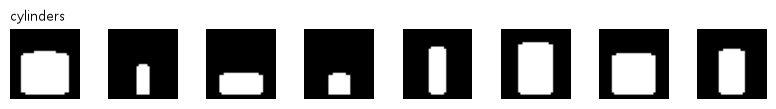

In [3]:
# 원기둥 그림 만들기: 높이 h · 너비 w 두 숫자 → 32×32 그림 (강의 10 ~ 13쪽 예)
# 왜 · 숫자 두 개로 그림 전체가 정해지는 데이터를 만들어 압축의 뜻을 보이기 위해
def cylinder(h, w, size=32):                 # 높이 · 너비 → 그림
    yy, xx = np.mgrid[0:size, 0:size]        # 칸마다 (세로, 가로) 좌표
    dx = (xx - size / 2 + 0.5) / (w / 2)     # 가운데에서 떨어진 가로 거리 (너비 기준)
    bottom = size - 4                        # 바닥 위치
    top = bottom - h                         # 윗면 위치 = 바닥 - 높이
    body = (np.abs(dx) <= 1) & (yy >= top) & (yy <= bottom)  # 몸통 = 직사각형
    # 위 · 아래 타원
    caps = (dx ** 2 + ((yy - top) / 2) ** 2 <= 1) | (dx ** 2 + ((yy - bottom) / 2) ** 2 <= 1)
    return (body | caps).astype(np.float32)  # 원기둥 칸 = 1 · 바깥 = 0


# 숫자 2개가 그림 1,024칸을 정함
# 왜 · 많은 칸이 실제로는 적은 숫자로 설명된다는 것을 확인하기 위해
img = cylinder(12, 10)                                         # 높이 12 · 너비 10
print("그림 모양:", img.shape, "| 칸 수:", img.size, "| 칠해진 칸:", int(img.sum()))  # 32×32
taller = cylinder(16, 10)                                      # 높이만 +4
print("높이 +4 → 바뀐 칸:", int((img != taller).sum()), "개")  # 픽셀로 고치면 이만큼


# 데이터셋 2,000장: 높이 · 너비를 무작위로 (라벨은 확인용으로만 따로 보관)
# 왜 · 라벨 없이 학습할 데이터를 만들고 라벨은 확인용으로만 남기기 위해
rng = np.random.default_rng(0)                                  # 난수 고정
H = rng.uniform(6, 22, 2000)                                    # 높이 6 ~ 22칸
W = rng.uniform(6, 22, 2000)                                    # 너비 6 ~ 22칸
# (2000, 1, 32, 32)
X = torch.tensor(np.stack([cylinder(h, w) for h, w in zip(H, W)])).unsqueeze(1).to(device)
print("데이터:", tuple(X.shape), "| 값:", X.unique().tolist())  # 0과 1만
show([("cylinders", X)])                                        # 앞 8장

**결과** · 예측 정답은 40개 — 잠재 공간에서는 숫자 1개(높이)만 바꾸면 됨

- `그림 모양: (32, 32) | 칸 수: 1024 | 칠해진 칸: 146` — 숫자 1,024개로 된 그림 · 원기둥은 146칸
- `높이 +4 → 바뀐 칸: 40 개` — 픽셀로 고치면 40칸을 하나하나 바꿔야 함 (강의 13쪽)
- `데이터: (2000, 1, 32, 32) | 값: [0.0, 1.0]` — 2,000장 · 칸 값은 0(바깥)과 1(원기둥)뿐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>픽셀 공간 (1,024개)</td><td>칸마다 따로 · 높이를 바꾸려면 많은 칸을 고침</td><td>그림을 저장 · 표시할 때</td></tr>
<tr><td>잠재 공간 (2개)</td><td>높이 · 너비 같은 큰 성질이 축</td><td>성질을 바꾸거나 비교할 때</td></tr>
<tr><td>매핑 함수 f</td><td>잠재 좌표 → 그림 (이 노트북은 <code>cylinder</code>가 직접 그림)</td><td>오토인코더에서는 디코더가 이 일을 배움</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 라벨(H · W)은 '정답 확인용'으로만 따로 보관 · 오토인코더 학습에는 쓰지 않음 (2-3)
> - 실제 사진은 성질이 2개로 딱 떨어지지 않음 → 몇 개가 필요한지는 실험으로 정함 (5장)

> ✅ **한 줄 정리** · 표현 학습은 고차원 그림을 그 그림을 정하는 몇 개의 숫자(잠재 공간)로 나타내는 것이고, 원기둥은 높이 · 너비 2개면 충분하다.

**딥러닝 코드에서는**

- 오토인코더 · VAE · GAN의 잠재 벡터가 이 '좌표'
- 사전학습 모델의 특징 벡터도 이미지를 짧은 숫자 목록으로 요약한 것

---
## 2. 오토인코더 구조

> **이 장의 흐름**
>
> - 1장의 원기둥 그림을 1,024 → 2로 줄였다 되돌리는 모델을 만들고 층마다 모양을 찍음
> - 그다음 강의 그림의 큰 모델 크기를 세고, 손실을 무엇으로 재는지 확인

<img src="images/pfa1_structure.png" alt="인코더 → 잠재 벡터 → 디코더" width="728">

**파이프라인 위치** · ③ 모델 설계 → ④ 손실 정하기

### 2-1. `A` 인코더 · 잠재 벡터 · 디코더 · `nn.Sequential` · `nn.Sigmoid` <sub>PDF 15 ~ 21쪽</sub>

> 🎯 **그림 한 장이 인코더와 디코더를 지나며 모양이 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 인코더는 **요약하는 사람**, 디코더는 **요약만 보고 다시 그리는 사람**.
- 둘 사이에 오가는 짧은 메모가 잠재 벡터.

**실행 흐름**

1. AutoEncoder 정의 (잠재 2)
2. 한 장을 층마다 통과
3. 층 이름 · 나온 모양 찍기

**먼저 예측** · 인코더 끝(잠재 벡터)의 모양은? — 답은 코드 실행 결과 아래에

In [4]:
# 인코더 · 디코더 · 잠재 벡터 (강의 17 ~ 21쪽): 1,024 → 128 → 2 → 128 → 1,024
# 왜 · 강의의 구조를 그대로 코드로 옮겨 각 부분의 역할을 보기 위해
class AutoEncoder(nn.Module):          # nn.Module을 물려받은 모델
    def __init__(self, latent_dim=2):  # 잠재 크기를 인자로
        super().__init__()             # 부모 초기화
        self.encoder = nn.Sequential(  # 줄이는 쪽
            nn.Flatten(), nn.Linear(1024, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(  # 되돌리는 쪽
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 1024), nn.Sigmoid())

    # 왜 · 입력 → 잠재 벡터 → 복원의 흐름을 한 메서드로 묶기 위해
    def forward(self, x):                              # model(x) 할 때 실행되는 길
        z = self.encoder(x)                            # 잠재 벡터
        return self.decoder(z).reshape(-1, 1, 32, 32)  # 1,024 → 그림 모양


# 한 장을 층마다 통과시키며 모양 찍기
# 왜 · 층을 지날 때 모양이 어떻게 줄었다 늘어나는지 확인하기 위해
torch.manual_seed(0)                                      # 같은 시작 가중치
ae = AutoEncoder(2).to(device)                            # 잠재 2 = 높이 · 너비 자리
h = X[:1]                                                 # 한 장 (1, 1, 32, 32)
print(f"{'입력':<10}", tuple(h.shape))                    # 출발 모양
for layer in list(ae.encoder) + list(ae.decoder):         # 인코더 → 디코더 층을 차례로
    h = layer(h)                                          # 층 하나 통과
    print(f"{type(layer).__name__:<10}", tuple(h.shape))  # 층 이름 + 나온 모양
print(f"{'reshape':<10}", tuple(ae(X[:1]).shape))         # forward 끝의 접기

입력         (1, 1, 32, 32)
Flatten    (1, 1024)


Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 2)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 1024)
Sigmoid    (1, 1024)
reshape    (1, 1, 32, 32)


**결과** · 예측 정답은 `(1, 2)` — 한 장이 숫자 2개로 줄어듦

- `Flatten (1, 1024)` — 32×32 그림을 1,024칸 한 줄로 폄
- `Linear (1, 2)` — 인코더 끝 = 잠재 벡터 2칸 (높이 · 너비 자리)
- `Sigmoid (1, 1024)` — 디코더 끝 · 칸마다 0~1
- `reshape (1, 1, 32, 32)` — 다시 그림 모양 → 입력과 칸마다 비교 가능

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>인코더 <code>encoder</code></td><td>1,024 → 128 → 2 줄이기</td><td>요약(잠재 벡터)만 필요할 때</td></tr>
<tr><td>디코더 <code>decoder</code></td><td>2 → 128 → 1,024 되돌리기 (인코더를 거꾸로)</td><td>잠재 벡터에서 그림을 만들 때</td></tr>
<tr><td>끝의 <code>nn.Sigmoid()</code></td><td>출력을 0~1로 · 입력 칸 값과 같은 범위</td><td>입력을 0~1로 맞췄을 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 디코더 첫 Linear의 입력 개수 = 잠재 크기 · 다르면 `mat1 and mat2 shapes` 에러
> - `reshape(-1, 1, 32, 32)`를 빠뜨리면 출력이 (장, 1024)라 입력과 모양이 다름

> ✅ **한 줄 정리** · 인코더는 그림을 잠재 벡터로 줄이고 디코더는 거꾸로 되돌리며, 출력은 입력과 같은 모양이어야 손실을 잴 수 있다.

**딥러닝 코드에서는**

- `self.encoder` · `self.decoder` 두 부분으로 나눠 두면 잠재 벡터만 따로 꺼낼 수 있음 (3-2)
- 자세한 크기 계산 · Conv 버전은 오토인코더-1 1-2 · 3-5

### 2-2. `B` 강의 그림의 큰 모델 · 파라미터 세기 · `device="meta"` · `p.numel()` <sub>PDF 22 ~ 24쪽</sub>

> 🎯 **강의 23쪽처럼 480×360 사진을 10개로 줄이는 모델은 가중치가 몇 개인가?**

💡 **쉽게 말하면**

- 층마다 '받는 개수 × 내는 개수 + 내는 개수'만큼 가중치가 있음.
- 입력이 크면 첫 층과 마지막 층이 거의 전부를 차지함.

**실행 흐름**

1. 강의 그림의 층 크기 7개
2. meta 장치로 층 만들기 (메모리 안 씀)
3. 층별 · 전체 파라미터 · 원기둥 AE와 비교

**먼저 예측** · 가장 큰 층 하나는 파라미터가 대략 몇 개일까? — 답은 코드 실행 결과 아래에

In [5]:
# 강의 23쪽 그림의 층 크기로 파라미터 수 세기 (meta 장치 = 모양만 만들고 메모리는 안 씀)
# 왜 · 메모리를 쓰지 않고 큰 모델의 크기만 세어 보기 위해
sizes = [480 * 360, 1000, 500, 10, 500, 1000, 480 * 360]  # 입력 → 은닉 → 잠재 10 → 은닉 → 출력
big = nn.Sequential(*[nn.Linear(a, b, device="meta") for a, b in zip(sizes, sizes[1:])])  # 층 6개
for layer in big:                                         # 층마다
    n = sum(p.numel() for p in layer.parameters())        # 가중치 + 편향 개수
    print(f"{layer.in_features:>7,} → {layer.out_features:>7,} | 파라미터 {n:>11,}")  # 층별
total = sum(p.numel() for p in big.parameters())          # 전체
print(f"전체 {total:,}개 | float32로 약 {total * 4 / 1024 ** 3:.2f} GB")  # 4바이트씩


# 이 노트북의 작은 원기둥 오토인코더와 비교
# 왜 · 실습 모델이 강의 모델보다 얼마나 작은지 비교하기 위해
small = sum(p.numel() for p in ae.parameters())            # 2-1 모델
print(f"원기둥 AE(1,024 → 128 → 2) 파라미터 {small:,}개")  # 훨씬 작음

172,800 →   1,000 | 파라미터 172,801,000
  1,000 →     500 | 파라미터     500,500
    500 →      10 | 파라미터       5,010
     10 →     500 | 파라미터       5,500
    500 →   1,000 | 파라미터     501,000
  1,000 → 172,800 | 파라미터 172,972,800
전체 346,785,810개 | float32로 약 1.29 GB
원기둥 AE(1,024 → 128 → 2) 파라미터 263,938개


**결과** · 예측 정답은 약 1억 7천만 개 — 첫 층(172,800 → 1,000)과 마지막 층이 거의 전부

- `172,800 → 1,000 | 파라미터 172,801,000` — 172800 × 1000 + 1000
- `1,000 → 172,800 | 파라미터 172,972,800` — 마지막 층 · 1000 × 172800 + 172800
- `전체 346,785,810개 | float32로 약 1.29 GB` — 가중치만 1GB가 넘음
- `원기둥 AE(1,024 → 128 → 2) 파라미터 263,938개` — 이 노트북 모델은 그 천분의 일도 안 됨

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>완전 연결(Linear)로 깊게</td><td>모든 입력 칸이 모든 다음 칸과 연결 · 파라미터 폭증</td><td>작은 입력 · 표 데이터</td></tr>
<tr><td>CNN(Conv)으로 줄이기</td><td>같은 필터를 옮겨 씀 · 파라미터가 훨씬 적음</td><td>큰 이미지 (강의 22쪽: 최근엔 ReLU CNN)</td></tr>
<tr><td><code>device="meta"</code></td><td>모양만 만들고 메모리를 안 씀</td><td>큰 모델의 크기만 미리 셀 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 1.29 GB는 가중치만 · 학습하면 기울기 · Adam 상태까지 몇 배로 늘어남
> - 큰 이미지를 Linear로 펴는 구조는 쓰지 않음 → Conv 오토인코더 (오토인코더-1 3장)

> ✅ **한 줄 정리** · Linear 층의 파라미터는 입력 × 출력 + 출력이라, 큰 이미지를 펴서 넣으면 첫 층과 마지막 층이 수억 개로 커진다.

**딥러닝 코드에서는**

- 모델 설계 뒤 `sum(p.numel() for p in model.parameters())`로 크기부터 확인
- 이미지 오토인코더는 Conv2d · ConvTranspose2d로 만듦 (미션 5)

### 2-3. `A` 손실 = 입력과 출력의 차이 · `F.mse_loss(out, x)` <sub>PDF 25 · 26쪽</sub>

> 🎯 **라벨이 없는데 손실은 무엇과 무엇을 비교해 재는가?**

💡 **쉽게 말하면**

- 정답 자리에 **입력 자신**을 둠.
- 출력이 입력과 칸마다 얼마나 다른지(MSE)를 줄이도록 배움.

**실행 흐름**

1. 학습 전 모델로 8장 복원
2. MSE를 직접 계산 · `F.mse_loss`와 비교
3. 손실에 쓰는 두 텐서 모양 확인

**먼저 예측** · 학습 전 모델의 출력은 0~1 중 어디쯤에 몰려 있을까? — 답은 코드 실행 결과 아래에

In [6]:
# 학습 전 모델의 출력과 입력 비교 (강의 25 · 26쪽: 손실 = 입력과 출력의 차이)
# 왜 · 손실이 입력과 출력의 차이라는 것을 학습 전 결과로 먼저 보기 위해
x = X[:8]                                                            # 8장
with torch.no_grad():                                                # 기울기 계산 끔 (보기만)
    out = ae(x)                                                      # 학습 전 복원
by_hand = ((out - x) ** 2).mean().item()                             # 칸마다 (차이)² → 평균
print(f"직접 계산 MSE {by_hand:.4f} | F.mse_loss {F.mse_loss(out, x).item():.4f}")  # 같은 값
print(f"출력 범위 {out.min().item():.2f} ~ {out.max().item():.2f}")  # Sigmoid → 0~1 사이


# 정답 자리에는 입력 자신 → 라벨(H · W)은 손실에 들어가지 않음
# 왜 · 오토인코더는 라벨 없이 입력 자신을 정답으로 쓴다는 것을 확인하기 위해
# 출력 ↔ 입력
print("손실에 쓰는 것:", tuple(out.shape), "vs", tuple(x.shape), "(같은 모양 · 같은 그림)")

직접 계산 MSE 0.2508 | F.mse_loss 0.2508
출력 범위 0.36 ~ 0.63
손실에 쓰는 것: (8, 1, 32, 32) vs (8, 1, 32, 32) (같은 모양 · 같은 그림)


**결과** · 예측 정답은 0.5 근처 (0.36 ~ 0.63) — 아직 아무것도 안 배워 회색에 가까움

- `직접 계산 MSE 0.2508 | F.mse_loss 0.2508` — 칸마다 (차이)² 평균 = `F.mse_loss`
- `출력 범위 0.36 ~ 0.63` — Sigmoid 출력이 0.5 근처 · 0과 1인 입력과 멂
- `손실에 쓰는 것: (8, 1, 32, 32) vs (8, 1, 32, 32) (같은 모양 · 같은 그림)` — 정답 = 입력 · 라벨 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>지도 학습 손실</td><td>출력 ↔ 사람이 붙인 라벨</td><td>분류 · 회귀</td></tr>
<tr><td>오토인코더 손실</td><td>출력 ↔ <strong>입력 자신</strong></td><td>라벨 없이 압축 · 복원</td></tr>
<tr><td>노이즈 제거 손실 (4-1)</td><td>노이즈 입력의 출력 ↔ 깨끗한 원본</td><td>손상을 되돌릴 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 라벨이 없다 ≠ 정답이 없다 · 정답 자리에 입력이 들어갈 뿐
> - 출력과 입력의 모양이 다르면 손실을 잴 수 없음 (2-1의 reshape)

> ✅ **한 줄 정리** · 오토인코더는 출력과 입력 자신의 차이(MSE)를 손실로 써서, 라벨 없이도 학습할 수 있다.

**딥러닝 코드에서는**

- `loss = F.mse_loss(model(x), x)` — 분류의 `F.cross_entropy(model(x), y)`에서 `y` 자리만 `x`
- 이 한 줄을 바꾸면 노이즈 제거(4-1) · 다른 요구로 확장됨

---
## 3. 학습과 잠재 공간

> **이 장의 흐름**
>
> - 2장 모델을 강의 26쪽의 3단계로 학습해 복원을 비교
> - 그다음 잠재 좌표가 실제 높이 · 너비를 담았는지 보고, 좌표를 옮겨 새 그림을 만듦

<img src="images/pfa1_train.png" alt="x → z → x̂ → 차이 → 가중치 수정" width="728">

**파이프라인 위치** · ⑤ 학습 → ⑥ 평가 → ⑦ 잠재 공간 활용

### 3-1. `A` 학습 3단계 · 학습 전과 후 · `loss.backward()` · `opt.step()` <sub>PDF 25 · 26쪽</sub>

> 🎯 **강의 26쪽의 학습 3단계를 코드로 쓰면 어떤 모양이고, 학습 뒤 복원은 얼마나 좋아지는가?**

💡 **쉽게 말하면**

- ① 입력 x를 인코더로 z로 ② 디코더로 x̂로 ③ x와 x̂의 차이를 줄이도록 가중치를 고침.
- 이 세 단계를 64장씩 묶어 30번 반복.

**실행 흐름**

1. `train` 함수 정의
2. 같은 출발점에서 30 epoch 학습
3. 학습 전 · 후 MSE · 그림 3줄

**먼저 예측** · 학습 뒤 복원 MSE는 학습 전(0.25)의 몇 분의 1쯤 될까? — 답은 코드 실행 결과 아래에

  epoch  1  loss 0.0532


  epoch 15  loss 0.0191


  epoch 30  loss 0.0103
복원 MSE  학습 전 0.2509 → 학습 후 0.0122


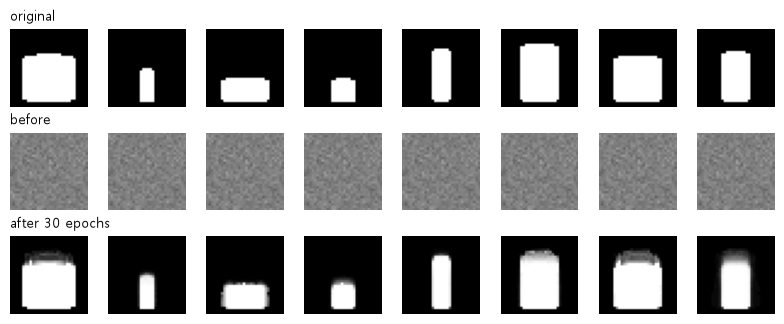

In [7]:
# 학습 함수 (강의 26쪽 1 → 2 → 3단계를 묶음마다 반복)
# 왜 · 강의의 학습 3단계를 그대로 함수로 만들어 여러 실험에 다시 쓰기 위해
def train(model, data, epochs=30, target=None, seed=0):               # 학습 후 모델을 돌려줌
    torch.manual_seed(seed)                                           # 섞는 순서 고정
    target = data if target is None else target                       # 정답: 따로 안 주면 입력 자신
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)               # 인코더 · 디코더 가중치 전부
    for epoch in range(epochs):                                       # 전체를 epochs번
        perm = torch.randperm(len(data), device=device)               # 번호 섞기
        for i in range(0, len(data), 64):                             # 64장씩
            b = perm[i:i + 64]                                        # 이번 묶음 번호
            opt.zero_grad()                                           # 앞 묶음 기울기 비우기
            loss = F.mse_loss(model(data[b]), target[b])              # ① x → z ② z → x̂ ③ 차이
            loss.backward()                                           # 기울기 계산
            opt.step()                                                # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):                 # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1:>2}  loss {loss.item():.4f}")  # 마지막 묶음 loss
    return model.eval()                                               # 평가 모드로 돌려줌


# 같은 출발점에서 학습 전 · 후 비교
# 왜 · 같은 seed에서 시작해 학습 효과만 비교하기 위해
torch.manual_seed(0)                                                           # 2-1과 같은 출발점
ae2 = train(AutoEncoder(2).to(device), X)                                      # 잠재 2 · 30 epoch
with torch.no_grad():                                                          # 보기만
    before, after = F.mse_loss(ae(X), X).item(), F.mse_loss(ae2(X), X).item()  # 2,000장 전체
print(f"복원 MSE  학습 전 {before:.4f} → 학습 후 {after:.4f}")  # 같은 데이터 · 같은 계산
with torch.no_grad():                                                          # 보기만
    show([("original", X), ("before", ae(X)), ("after 30 epochs", ae2(X))])    # 3줄

**결과** · 예측 정답은 약 20분의 1 (0.2509 → 0.0122)

- `epoch 1 loss 0.0532` — 첫 epoch 마지막 묶음
- `epoch 30 loss 0.0103` — 내려가는 모양만 봄 (한 묶음 값)
- `복원 MSE 학습 전 0.2509 → 학습 후 0.0122` — 같은 데이터 전체 · 같은 계산 · 그림 셋째 줄이 원기둥 모양으로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td><code>opt.zero_grad()</code></td><td>앞 묶음 기울기를 비움</td><td>묶음마다 맨 앞</td></tr>
<tr><td><code>loss.backward()</code></td><td>손실 → 모든 가중치의 기울기</td><td>손실을 구한 직후</td></tr>
<tr><td><code>opt.step()</code></td><td>기울기 반대쪽으로 가중치 갱신</td><td>backward 바로 뒤</td></tr>
<tr><td><code>model.eval()</code></td><td>평가 모드 (이 모델은 Dropout이 없어 결과는 같음)</td><td>학습을 마친 뒤</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - epoch마다 찍은 loss는 마지막 한 묶음 값 → 모델 비교는 전체 MSE로
> - seed를 같게 해야 '학습 전 · 후' 차이가 학습 때문이라고 말할 수 있음

> ✅ **한 줄 정리** · 오토인코더 학습은 x → z → x̂ → 차이 → 가중치 수정을 묶음마다 반복하는 것이고, 라벨 없이도 복원 오차가 크게 줄어든다.

**딥러닝 코드에서는**

- 분류 학습 루프와 같은 모양 · 손실 한 줄만 다름
- 직접 빈칸을 채우는 실습은 파일별 2 (PRACTICE_P2)

### 3-2. `A` 잠재 공간 읽기 · `model.encoder(x)` · `np.linalg.lstsq` <sub>PDF 9 ~ 14쪽</sub>

> 🎯 **라벨 없이 배운 잠재 좌표 2개는 실제 높이 · 너비를 담고 있는가?**

💡 **쉽게 말하면**

- 2,000장을 인코더에만 넣으면 장마다 점 하나.
- 그 점으로 높이 · 너비를 얼마나 맞힐 수 있는지(R²)를 재 봄.

**실행 흐름**

1. 인코더만 통과 → (2000, 2)
2. 잠재 → 높이 · 너비 직선 맞춤 R²
3. 높이 · 너비로 색칠한 산점도

**먼저 예측** · 잠재 축 하나가 '높이', 다른 하나가 '너비'로 딱 나뉠까? — 답은 코드 실행 결과 아래에

잠재 좌표 모양: (2000, 2)
높이  R² 0.649 | 축1 상관 +0.67 | 축2 상관 +0.42
너비  R² 0.800 | 축1 상관 -0.40 | 축2 상관 +0.82


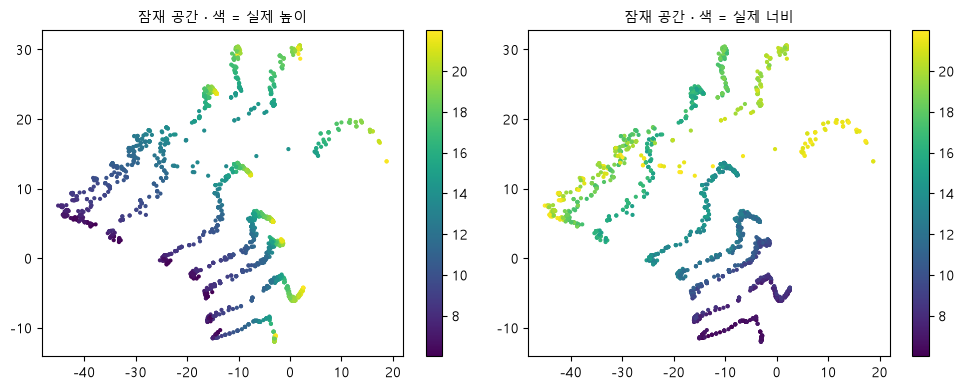

In [8]:
# 2,000장을 인코더에만 통과 → 잠재 좌표 (2000, 2)
# 왜 · 학습된 잠재 공간에 그림들이 어떻게 놓였는지 보기 위해
with torch.no_grad():                 # 꺼내기만
    Z = ae2.encoder(X).cpu().numpy()  # 한 장 = 점 하나
print("잠재 좌표 모양:", Z.shape)     # (장 수, 2)


# 잠재 두 축으로 진짜 높이 · 너비를 얼마나 맞힐 수 있나 (직선 맞춤의 R²)
# 왜 · 잠재 공간이 높이 · 너비 정보를 담았는지 숫자로 확인하기 위해
A = np.c_[Z, np.ones(len(Z))]                                           # [z1, z2, 1]
for name, t in [("높이", H), ("너비", W)]:                              # 확인용 라벨 두 개
    coef, *_ = np.linalg.lstsq(A, t, rcond=None)                        # z로 t를 맞추는 직선
    r2 = 1 - ((A @ coef - t) ** 2).sum() / ((t - t.mean()) ** 2).sum()  # 1에 가까울수록 잘 맞음
    print(f"{name}  R² {r2:.3f} | 축1 상관 {np.corrcoef(Z[:, 0], t)[0, 1]:+.2f}"  # R² · 축별 상관
          f" | 축2 상관 {np.corrcoef(Z[:, 1], t)[0, 1]:+.2f}")


# 같은 점에 높이 · 너비로 색만 입혀 보기 (라벨은 학습 뒤 색칠에만)
# 왜 · 라벨은 학습 뒤 색칠에만 써서 잠재 공간의 구조를 눈으로 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(10, 4))                  # 왼쪽 높이 · 오른쪽 너비
for ax, (name, t) in zip(axes, [("높이", H), ("너비", W)]):      # 두 그림
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=t, s=4, cmap="viridis")  # 잠재 평면의 점
    ax.set_title(f"잠재 공간 · 색 = 실제 {name}", fontsize=10)   # 어떤 색칠인지
    plt.colorbar(sc, ax=ax)                                      # 색 ↔ 값
plt.tight_layout()                                               # 간격 정리
plt.show()                                                       # 그림 출력

**결과** · 예측 정답은 딱 나뉘지는 않음 — 두 축이 높이 · 너비를 섞어서 담음 (축1은 높이 +0.67 · 너비 -0.40)

- `잠재 좌표 모양: (2000, 2)` — 한 장 = 잠재 평면의 점 하나
- `높이 R² 0.649 | 축1 상관 +0.67 | 축2 상관 +0.42` — 직선 하나로 높이의 65%를 설명
- `너비 R² 0.800 | 축1 상관 -0.40 | 축2 상관 +0.82` — 너비는 80% · 축2와 가까움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>강의 그림 (12쪽)</td><td>축이 '높이' · '너비'로 딱 나뉜 이상적인 모습</td><td>개념 설명</td></tr>
<tr><td>실제 학습 결과</td><td>축이 두 성질을 섞어 담음 · 휘어져 있을 수 있음</td><td>학습 뒤 확인할 때</td></tr>
<tr><td>R² (직선 맞춤)</td><td>잠재 → 성질을 직선으로 얼마나 맞히나 · 휘어진 관계는 낮게 나옴</td><td>담았는지 대략 볼 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - R²는 '직선' 기준이라 잠재가 휘어지게 담으면 낮게 나옴 → 0.649가 '못 배웠다'는 뜻은 아님
> - 축에 사람 말 이름을 붙일 근거는 없음 · 학습마다 축 방향이 달라짐

> ✅ **한 줄 정리** · 라벨 없이 배운 잠재 좌표도 높이 · 너비를 담지만, 강의 그림처럼 축 하나에 성질 하나로 딱 나뉘지는 않는다.

**딥러닝 코드에서는**

- 잠재 벡터를 다른 모델(분류 · 군집)의 입력으로 쓸 수 있음 (표현 학습)
- MNIST 잠재 2차원 산점도는 오토인코더-1 4장

### 3-3. `B` 잠재 공간에서 새 그림 만들기 · `model.decoder(z)` <sub>PDF 13 · 28쪽</sub>

> 🎯 **잠재 좌표를 '높이 방향'으로 옮겨 디코더에 넣으면 실제로 키 큰 원기둥이 나오는가?**

💡 **쉽게 말하면**

- 강의 13쪽: 높이를 키우려면 픽셀을 다 고치지 말고 잠재 공간의 높이에 더한 뒤 매핑 함수를 적용.
- 여기서는 '높이 방향'을 데이터로 찾아 z에 더하고 디코더로 그림.

**실행 흐름**

1. (높이, 너비) → z 직선 맞춤으로 높이 방향 찾기
2. z + 6 × 높이 방향
3. 디코더로 그려 실제 높이+6과 비교

**먼저 예측** · 잠재에서 옮긴 그림이 원래 복원보다 '실제 높이+6 원기둥'에 더 가까울까? — 답은 코드 실행 결과 아래에

고른 원기둥: 높이 6.3 · 너비 10.5
잠재 +6 그림 ↔ 실제 높이+6  MSE 0.0108
원래 복원   ↔ 실제 높이+6  MSE 0.0418


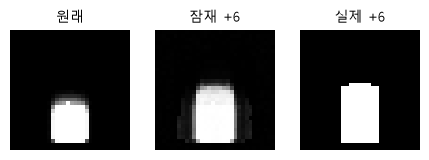

In [9]:
# 잠재 공간에서 '높이 방향'을 찾기: z ≈ (높이, 너비)를 직선으로 옮긴 것
# 왜 · 잠재 공간에서 뜻이 있는 방향을 찾아 새 그림을 만들기 위해
G = np.c_[H, W, np.ones(len(H))]           # [높이, 너비, 1]
M, *_ = np.linalg.lstsq(G, Z, rcond=None)  # (높이, 너비) → z 직선 맞춤
height_dir = M[0]                          # 높이 1칸당 z가 움직이는 방향


# 한 원기둥의 z에 '높이 +6'만큼 더해 디코더로 그리기 (강의 13쪽)
# 왜 · 잠재 벡터를 바꾸면 그림이 뜻대로 바뀌는지 확인하기 위해
k = 3                                                                            # 고를 원기둥 번호
z_new = torch.tensor(Z[k] + 6 * height_dir, dtype=torch.float32, device=device)  # 잠재에서 더하기
with torch.no_grad():                                                            # 그리기만
    made = ae2.decoder(z_new[None]).reshape(1, 1, 32, 32)                        # 새 그림
    same = ae2.decoder(torch.tensor(Z[k:k + 1], device=device)).reshape(1, 1, 32, 32)  # 원래 z 복원
truth = torch.tensor(cylinder(H[k] + 6, W[k]), device=device)[None, None]  # 실제 높이 +6 원기둥
print(f"고른 원기둥: 높이 {H[k]:.1f} · 너비 {W[k]:.1f}")                         # 출발점
print(f"잠재 +6 그림 ↔ 실제 높이+6  MSE {F.mse_loss(made, truth).item():.4f}")   # 가까울수록 작음
print(f"원래 복원   ↔ 실제 높이+6  MSE {F.mse_loss(same, truth).item():.4f}")    # 비교 기준
fig, axes = plt.subplots(1, 3, figsize=(4.5, 1.6))  # 원래 · 잠재 +6 · 실제
for ax, (name, im) in zip(axes, [("원래", same), ("잠재 +6", made), ("실제 +6", truth)]):  # 세 장
    ax.imshow(im[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)                       # 밝기 0~1
    ax.set_title(name, fontsize=10)                                              # 이름
    ax.axis("off")                                                               # 눈금 숨김
plt.tight_layout()                                                               # 간격 정리
plt.show()                                                                       # 그림 출력

**결과** · 예측 정답은 가까움 — MSE 0.0418 → 0.0108

- `고른 원기둥: 높이 6.3 · 너비 10.5` — 낮은 원기둥에서 출발
- `잠재 +6 그림 ↔ 실제 높이+6 MSE 0.0108` — 잠재에서 숫자를 더한 것만으로 키 큰 원기둥이 나옴
- `원래 복원 ↔ 실제 높이+6 MSE 0.0418` — 비교 기준 · 약 4배 멂

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>픽셀을 직접 고치기</td><td>바뀌는 칸(40개)을 하나하나 수정</td><td>작은 편집</td></tr>
<tr><td>잠재에서 옮기고 디코더</td><td>숫자 몇 개만 바꾸면 그림 전체가 자연스럽게 바뀜</td><td>성질을 바꾼 새 그림 (생성 · 편집)</td></tr>
<tr><td>잠재에서 아무 곳이나 뽑기</td><td>본 적 없는 자리면 이상한 그림</td><td>VAE가 이 문제를 다룸 (오토인코더-2 1-5)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 높이 방향은 학습 데이터 범위(6 ~ 22칸) 안에서만 믿을 수 있음
> - 그림 한 장의 결과 · 다른 원기둥에서는 오차가 다를 수 있음

> ✅ **한 줄 정리** · 잠재 공간에서 성질의 방향으로 좌표를 옮겨 디코더에 넣으면, 픽셀을 고치지 않고도 성질이 바뀐 새 그림을 만들 수 있다.

**딥러닝 코드에서는**

- 얼굴 생성 모델에서 '웃음 방향' 벡터를 더하는 편집과 같은 원리
- 강의 28쪽 Image Generation = 디코더만 쓰는 생성

---
## 4. 오토인코더 활용

> **이 장의 흐름**
>
> - 3장의 학습 함수에서 입력만 노이즈 낀 그림으로 바꿔 노이즈 제거를 배움
> - 그다음 원기둥만 배운 모델에 세모를 넣어 복원 오차로 이상을 찾음

<img src="images/pfa1_uses.png" alt="같은 구조 · 다른 입력과 쓰임" width="714">

**파이프라인 위치** · ⑦ 활용 (노이즈 제거 · 이상 탐지)

### 4-1. `B` 노이즈 제거 오토인코더 · `torch.randn` · `clamp(0, 1)` <sub>PDF 28 · 29쪽</sub>

> 🎯 **노이즈를 지우게 하려면 학습에서 무엇을 바꾸는가?**

💡 **쉽게 말하면**

- 얼룩진 그림을 보여 주고 **깨끗한 그림으로 답하게** 연습시킴.
- 구조는 그대로, 입력만 노이즈 낀 그림.

**실행 흐름**

1. 세기 0.3 노이즈 입히기 (고정 난수)
2. 입력 노이즈 · 정답 깨끗으로 학습
3. 노이즈 그대로 · 일반 AE · 노이즈 제거 AE 비교

**먼저 예측** · 깨끗한 그림만 배운 3-1 모델에 노이즈 그림을 넣으면 노이즈 그대로보다 나을까? — 답은 코드 실행 결과 아래에

  epoch  1  loss 0.0595


  epoch 15  loss 0.0144


  epoch 30  loss 0.0075
노이즈 그대로     MSE 0.0450
일반 AE(3-1)  → MSE 0.0546
노이즈 제거 AE → MSE 0.0062


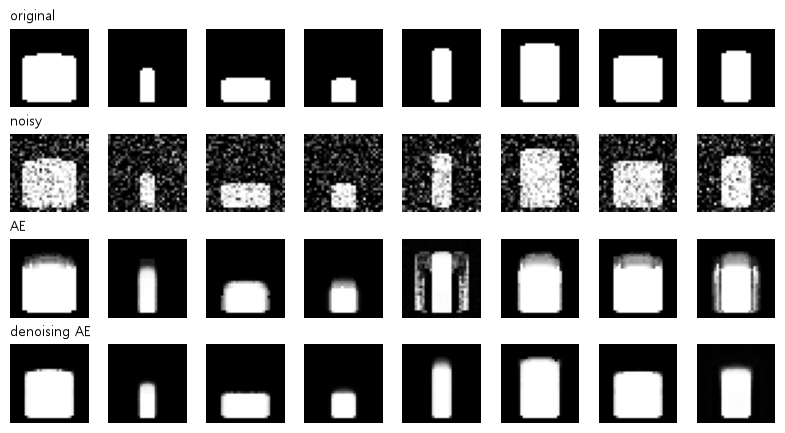

In [10]:
# 노이즈 제거 (강의 28 · 29쪽): 입력은 노이즈 낀 그림, 정답은 깨끗한 그림
# 왜 · 입력만 망가뜨리고 정답은 깨끗하게 두어 노이즈 제거를 학습시키기 위해
g = torch.Generator().manual_seed(1)                  # 노이즈 고정
Xn = (X + 0.3 * torch.randn(tuple(X.shape), generator=g).to(device)).clamp(0, 1)  # 세기 0.3
torch.manual_seed(0)                                  # 같은 출발점
dae = train(AutoEncoder(2).to(device), Xn, target=X)  # 정답 자리에 깨끗한 X


# 같은 노이즈 그림을 두 모델에 넣어 비교
# 왜 · 보통 모델과 노이즈 제거 모델의 차이를 같은 입력으로 비교하기 위해
with torch.no_grad():                                                   # 보기만
    print(f"노이즈 그대로     MSE {F.mse_loss(Xn, X).item():.4f}")      # 아무것도 안 했을 때
    print(f"일반 AE(3-1)  → MSE {F.mse_loss(ae2(Xn), X).item():.4f}")   # 깨끗한 그림만 배운 모델
    print(f"노이즈 제거 AE → MSE {F.mse_loss(dae(Xn), X).item():.4f}")  # 노이즈 → 깨끗을 배운 모델
    show([("original", X), ("noisy", Xn), ("AE", ae2(Xn)), ("denoising AE", dae(Xn))])  # 4줄

**결과** · 예측 정답은 아님 — 0.0546으로 노이즈 그대로(0.0450)보다도 나쁨

- `epoch 30 loss 0.0075` — 노이즈 → 깨끗을 배우는 중
- `노이즈 그대로 MSE 0.0450` — 아무것도 안 했을 때 (기준선)
- `일반 AE(3-1) → MSE 0.0546` — 노이즈를 본 적 없는 모델은 오히려 나빠짐
- `노이즈 제거 AE → MSE 0.0062` — 같은 구조로 노이즈를 거의 지움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>일반 AE</td><td>입력 x · 정답 x</td><td>깨끗한 데이터의 압축 · 특징</td></tr>
<tr><td>노이즈 제거 AE (DAE)</td><td>입력 노이즈 낀 x · 정답 깨끗한 x</td><td>손상된 입력을 되돌릴 때</td></tr>
<tr><td>자세한 비교</td><td>노이즈 세기 · 가림 손상 · 문서 복원</td><td>오토인코더-2 1 · 2장</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 평가 노이즈는 고정 난수로 한 번만 만들어 모든 모델에 같이 씀
> - 연습한 세기 · 종류의 손상에서만 잘 동작

> ✅ **한 줄 정리** · 노이즈 제거 오토인코더는 구조를 그대로 두고 입력만 망가뜨려, 깨끗한 원본을 내도록 배운다.

**딥러닝 코드에서는**

- 미션 5의 문서 복원이 이 짝(손상 문서 → 깨끗한 문서)
- 데이터 증강처럼 학습 입력에 실제와 비슷한 손상을 넣음

### 4-2. `B` 복원 오차로 이상 찾기 · `quantile(0.9)` <sub>PDF 15쪽</sub>

> 🎯 **원기둥만 배운 오토인코더는 처음 보는 세모를 어떻게 알아보는가?**

💡 **쉽게 말하면**

- 원기둥만 수천 번 그려 본 사람에게 세모를 주면 원기둥처럼 그려 버림.
- 원본과 많이 달라진 정도(복원 오차)가 '처음 보는 것'의 신호.

**실행 흐름**

1. 세모 200장 만들기
2. 원기둥 · 세모 한 장마다 복원 오차
3. 원기둥 오차의 90% 지점을 임곗값으로

**먼저 예측** · 세모의 복원 오차 중앙값은 원기둥보다 몇 배쯤 클까? — 답은 코드 실행 결과 아래에

In [11]:
# 원기둥만 배운 모델에 '처음 보는 모양'(세모)을 넣으면? (강의 15쪽: 이상 탐지에 활용)
# 왜 · 복원 오차로 처음 보는 데이터를 찾아내는 원리를 보이기 위해
def triangle(h, w, size=32):              # 처음 보는 모양 (세모)
    yy, xx = np.mgrid[0:size, 0:size]     # 칸마다 좌표
    bottom, top = size - 4, size - 4 - h  # 바닥 · 꼭대기
    half = (yy - top) / h * w / 2         # 내려갈수록 넓어지는 반폭
    inside = (yy >= top) & (yy <= bottom) & (np.abs(xx - size / 2 + 0.5) <= half)  # 세모 안
    return inside.astype(np.float32)      # 세모 = 1


# 왜 · 학습과 다른 seed로 처음 보는 세모 그림을 만들기 위해
rng2 = np.random.default_rng(1)                                             # 난수 고정
tri = np.stack([triangle(h, w) for h, w in rng2.uniform(8, 22, (200, 2))])  # 세모 200장
T = torch.tensor(tri).unsqueeze(1).to(device)                               # (200, 1, 32, 32)
with torch.no_grad():                                                       # 보기만
    err_c = ((ae2(X[:200]) - X[:200]) ** 2).flatten(1).mean(1)              # 원기둥 한 장마다 오차
    err_t = ((ae2(T) - T) ** 2).flatten(1).mean(1)                          # 세모 한 장마다 오차
print(f"원기둥 200장 복원 오차 중앙값 {err_c.median().item():.4f}")         # 배운 모양
print(f"세모   200장 복원 오차 중앙값 {err_t.median().item():.4f}")         # 처음 보는 모양
th = err_c.quantile(0.9).item()  # 원기둥 오차의 90% 지점 = 임곗값
# 잘못된 경보
print(f"임곗값 {th:.4f} | 원기둥을 이상으로 본 비율 {(err_c > th).float().mean().item():.0%}"
      f" | 세모를 이상으로 잡은 비율 {(err_t > th).float().mean().item():.0%}")

원기둥 200장 복원 오차 중앙값 0.0086
세모   200장 복원 오차 중앙값 0.0398
임곗값 0.0231 | 원기둥을 이상으로 본 비율 10% | 세모를 이상으로 잡은 비율 94%


**결과** · 예측 정답은 약 4.6배 (0.0086 → 0.0398)

- `원기둥 200장 복원 오차 중앙값 0.0086` — 배운 모양은 잘 되돌림
- `세모 200장 복원 오차 중앙값 0.0398` — 처음 보는 모양은 오차가 큼
- `임곗값 0.0231 | 원기둥을 이상으로 본 비율 10% | 세모를 이상으로 잡은 비율 94%` — 임곗값을 원기둥 오차로 정하면 세모 대부분을 잡음 · 원기둥 10%는 잘못된 경보

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>임곗값 낮게</td><td>이상을 많이 잡지만 잘못된 경보도 많음</td><td>놓치면 큰일일 때</td></tr>
<tr><td>임곗값 높게</td><td>확실한 것만 이상 · 놓침 증가</td><td>잘못된 경보 비용이 클 때</td></tr>
<tr><td>자세한 비교</td><td>정밀도 · 재현율 · 임곗값 4가지</td><td>오토인코더-2 5 · 6장</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 임곗값은 정상(원기둥) 데이터의 오차로 정함 · 세모 결과를 보고 고르면 안 됨
> - 같은 200장으로 임곗값을 정하고 비율도 쟀음 → 실제로는 검증용 정상 데이터를 따로 둠

> ✅ **한 줄 정리** · 정상만 배운 오토인코더는 처음 보는 입력을 잘 되돌리지 못하므로, 복원 오차가 임곗값보다 크면 이상으로 본다.

**딥러닝 코드에서는**

- 불량품 검사 · 심전도 이상 탐지(미션 5 심화)와 같은 원리
- 학습 데이터에 이상이 섞이면 이상도 잘 복원해 버림 → 정상만 골라 학습

---
## 5. 종합 실습 · 잠재 크기 1 · 2 · 8 비교

> **이 장의 흐름**
>
> - 1 ~ 3장을 한 번에 사용
> - 잠재 크기만 1 · 2 · 8로 바꿔 같은 조건으로 학습하고 복원 오차 · 성질을 담은 정도 · 그림을 비교

<img src="images/pfa1_practice.png" alt="성질 2개 · 잠재 1 · 2 · 8" width="714">

**파이프라인 위치** · ③ 모델 설계 → ⑤ 학습 → ⑥ 평가 → ⑦ 설계 선택

> 🎯 **성질이 2개(높이 · 너비)인 원기둥에는 잠재 2가 딱 맞고, 8은 남을까?**

💡 **쉽게 말하면**

- 메모 칸을 1 · 2 · 8칸으로 바꿔 같은 연습을 시켜 봄.
- 1칸이면 높이와 너비를 한 칸에 우겨넣어야 해서 흐려짐.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>잠재 1 · 8 학습 (2는 3-1 모델 그대로 · 모두 같은 조건)</td><td>2-1 <code>AutoEncoder</code> · 3-1 <code>train</code></td></tr>
<tr><td>2</td><td>복원 MSE · 높이와 너비 R²</td><td>2-3 <code>F.mse_loss</code> · 3-2 <code>lstsq</code></td></tr>
<tr><td>3</td><td>같은 8장을 세 모델로 복원해 나란히</td><td>0장 <code>show</code></td></tr>
</tbody></table>

**먼저 예측** · 잠재 8의 복원 오차는 잠재 2보다 작을까? — 답은 코드 실행 결과 아래에

In [12]:
# 1단계: 잠재 크기 1 · 2 · 8로 같은 조건 학습 (2는 3-1 모델 그대로)
# 왜 · 잠재 크기만 바꿔 공정하게 비교하기 위해
models = {2: ae2}                                    # 잠재 크기 → 모델
for d in [1, 8]:                                     # 새로 학습할 크기
    print(f"잠재 {d} 학습")                          # 어느 모델의 loss인지
    torch.manual_seed(0)                             # 같은 출발점
    models[d] = train(AutoEncoder(d).to(device), X)  # 30 epoch


# 2단계: 복원 오차 · 높이와 너비를 얼마나 담았나 (R²)
# 왜 · 잠재 크기에 따라 복원 품질과 담긴 정보가 어떻게 바뀌는지 재기 위해
def r2_of(model):                                   # 잠재로 높이 · 너비를 맞힌 정도
    with torch.no_grad():                           # 꺼내기만
        z = model.encoder(X).cpu().numpy()          # 잠재 좌표
    A_ = np.c_[z, np.ones(len(z))]                  # 직선 맞춤 재료
    out = []                                        # (높이 R², 너비 R²)
    for t in (H, W):                                # 두 요인
        c, *_ = np.linalg.lstsq(A_, t, rcond=None)  # 맞춤
        out.append(1 - ((A_ @ c - t) ** 2).sum() / ((t - t.mean()) ** 2).sum())  # R²
    return out                                      # (높이 R², 너비 R²)


# 왜 · 잠재 크기마다 같은 방법으로 결과를 모으기 위해
for d in [1, 2, 8]:                                                              # 크기 순서로
    with torch.no_grad():                                                        # 보기만
        m = F.mse_loss(models[d](X), X).item()                                   # 2,000장 복원 오차
    rh, rw = r2_of(models[d])                                                    # 두 요인 R²
    print(f"잠재 {d} | 복원 MSE {m:.4f} | 높이 R² {rh:.3f} | 너비 R² {rw:.3f}")  # 한 줄 비교

잠재 1 학습
  epoch  1  loss 0.0579


  epoch 15  loss 0.0350


  epoch 30  loss 0.0469
잠재 8 학습
  epoch  1  loss 0.0558


  epoch 15  loss 0.0043


  epoch 30  loss 0.0068
잠재 1 | 복원 MSE 0.0432 | 높이 R² 0.212 | 너비 R² 0.426
잠재 2 | 복원 MSE 0.0122 | 높이 R² 0.649 | 너비 R² 0.800
잠재 8 | 복원 MSE 0.0061 | 높이 R² 0.975 | 너비 R² 0.968


**실행 흐름**

1. 같은 8장을 잠재 크기 1 · 2 · 8 모델로 복원
2. 원본과 함께 나란히 그리기

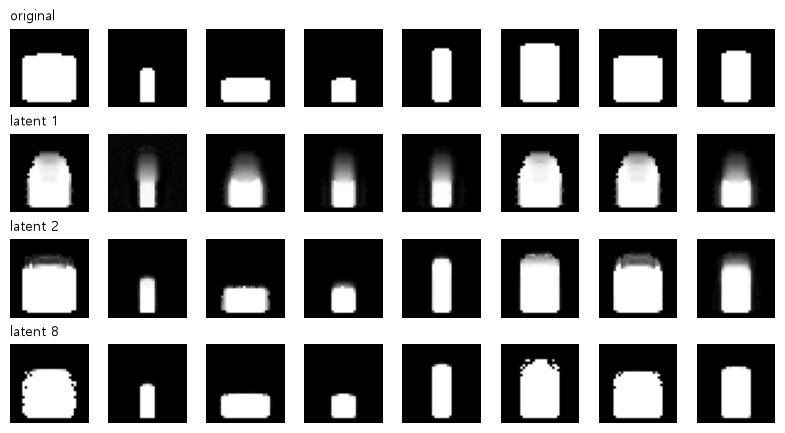

In [13]:
# 3단계: 같은 8장을 세 모델로 복원해 나란히
# 왜 · 세 모델의 복원 결과를 같은 그림으로 비교하기 위해
with torch.no_grad():                                                             # 그리기만
    show([("original", X)] + [(f"latent {d}", models[d](X)) for d in [1, 2, 8]])  # 원본 + 3줄

**결과** · 예측 정답은 작음 — 0.0122 → 0.0061 · 성질이 2개여도 칸이 넉넉하면 더 쉽게 되돌림

- `잠재 1 | 복원 MSE 0.0432 | 높이 R² 0.212 | 너비 R² 0.426` — 한 칸으로는 두 성질을 다 못 담음 · 그림도 흐림
- `잠재 2 | 복원 MSE 0.0122 | 높이 R² 0.649 | 너비 R² 0.800` — 성질 수와 같은 칸 · 3-1 · 3-2와 같은 값
- `잠재 8 | 복원 MSE 0.0061 | 높이 R² 0.975 | 너비 R² 0.968` — 칸이 넉넉해 두 성질을 거의 직선으로 담음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>잠재 1 (성질보다 적음)</td><td>두 성질을 한 칸에 → 복원이 흐리고 성질도 덜 담음</td><td>강한 압축이 꼭 필요할 때만</td></tr>
<tr><td>잠재 2 (성질 수와 같음)</td><td>그림으로 그릴 수 있음 · 잠재가 휘어지게 담기도 함</td><td>잠재 공간을 눈으로 볼 때</td></tr>
<tr><td>잠재 8 (넉넉함)</td><td>복원이 가장 좋고 성질을 직선으로 담음 · 압축은 약함</td><td>복원 품질 · 다른 모델의 입력이 목적일 때</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 실제 데이터는 성질이 몇 개인지 모름 → 크기 하나만 바꿔 같은 조건으로 비교해서 고름
> - 한 seed · 30 epoch 결과 · 숫자보다 방향을 볼 것

> ✅ **한 줄 정리** · 잠재 크기는 데이터를 정하는 성질 수보다 작으면 복원이 무너지고, 넉넉하면 복원은 좋아지지만 압축은 약해지므로 쓰임에 맞춰 고른다.

**딥러닝 코드에서는**

- MNIST에서 잠재 2 · 8 · 32를 비교한 실험은 오토인코더-1 4장
- `latent_dim`은 하이퍼파라미터 · 하나만 바꿔 같은 평가로 고름 (오토인코더-2 4장)

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. 차원 축소 · 표현 학습</td><td>480×360 사진은 172,800개 · 1000차원에선 거리 비율 1.2 · 원기둥은 숫자 2개로 결정</td><td>1-1 · 1-2</td></tr>
<tr><td>2. 구조 · 모양</td><td>1,024 → 128 → 2 → 128 → 1,024를 층마다 찍음 · 강의 그림 모델은 3억 개가 넘음</td><td>2-1 · 2-2</td></tr>
<tr><td>3. 라벨 없는 학습</td><td>손실 = 출력 ↔ 입력 · 학습 전 0.2509 → 학습 후 0.0122</td><td>2-3 · 3-1</td></tr>
<tr><td>4. 잠재 공간</td><td>잠재로 높이 R² 0.649 · 너비 0.800 · 높이 방향 +6으로 새 원기둥 (MSE 0.0108)</td><td>3-2 · 3-3</td></tr>
<tr><td>5. 활용 · 크기 고르기</td><td>노이즈 제거 0.0450 → 0.0062 · 세모 94% 잡음 · 잠재 1 · 2 · 8 비교</td><td>4장 · 5장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>표현 학습</td><td>고차원 그림을 정하는 몇 개의 숫자 = 잠재 공간</td><td>임베딩 · 특징 벡터</td></tr>
<tr><td><code>A</code></td><td>인코더 · 디코더</td><td>줄이기 · 되돌리기 · 출력 = 입력 모양</td><td><code>self.encoder</code> · <code>self.decoder</code></td></tr>
<tr><td><code>A</code></td><td>손실</td><td>정답 자리에 입력 자신 · MSE</td><td><code>F.mse_loss(model(x), x)</code></td></tr>
<tr><td><code>A</code></td><td>학습 3단계</td><td>x → z → x̂ → 차이 → 가중치 수정</td><td>zero_grad → backward → step</td></tr>
<tr><td><code>A</code></td><td>잠재 공간 읽기</td><td>성질을 담지만 축이 딱 나뉘지는 않음</td><td><code>model.encoder(x)</code></td></tr>
<tr><td><code>B</code></td><td>차원의 저주</td><td>차원이 커지면 거리가 다 비슷해짐</td><td>차원 축소의 이유</td></tr>
<tr><td><code>B</code></td><td>큰 Linear 모델</td><td>입력 × 출력 + 출력 · 큰 이미지는 Conv로</td><td><code>p.numel()</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>B</code></td><td>잠재 공간 편집</td><td>성질 방향으로 옮기고 디코더</td><td>생성 · 편집</td></tr>
<tr><td><code>B</code></td><td>노이즈 제거 · 이상 탐지</td><td>입력만 바꾸기 · 복원 오차 &gt; 임곗값</td><td>미션 5</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · 차원이 높아지면 거리 비교에 무슨 일이 생기는가?
- **1-2** · 원기둥 그림 1,024칸을 숫자 2개로 설명할 수 있는 이유는?
- **2-1** · 인코더와 디코더는 각각 무엇을 하는가?
- **2-2** · 큰 이미지를 Linear로 펴서 넣으면 무엇이 문제인가?
- **2-3** · 라벨 없이 손실은 무엇을 비교하는가?
- **3-1** · 학습 3단계를 말하면?
- **3-2** · 잠재 축 하나가 '높이'로 딱 나뉘었나?
- **3-3** · 잠재 공간에서 새 그림을 만드는 방법은?
- **4-1** · 노이즈 제거 오토인코더는 무엇을 바꾸는가?
- **4-2** · 이상 탐지의 임곗값은 무엇으로 정하는가?
- **5** · 잠재 크기는 몇이 정답인가?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 잠재 3인 인코더(`Flatten` → `Linear(1024, 128)` → `ReLU` → `Linear(128, 3)`)에 5장을 넣은 출력 모양
2. `nn.Linear(1024, 128)`의 파라미터 수
3. 입력 `[0, 1, 1, 0]` · 출력 `[0.5, 1, 0.5, 0]`의 MSE (소수 넷째 자리)

In [14]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 1-2의 `cylinder`로 높이 12 · 너비 10 원기둥의 너비를 +4 하면 바뀌는 칸은? 먼저 예측 후 실행
2. 4-1의 노이즈 세기를 0.6으로 바꾸면 '노이즈 그대로' MSE는 0.0450보다 커질까? 이유와 함께
3. 5장 표에서 잠재 1의 복원 MSE는 잠재 2의 몇 배인가?

In [15]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 가장 먼 거리와 가장 가까운 거리의 비율이 1에 가까워져 모든 점이 비슷하게 멂
- **1-2** · 그림이 높이 · 너비 두 숫자로 완전히 정해지기 때문
- **2-1** · 인코더는 그림을 잠재 벡터로 줄이고 디코더는 잠재 벡터에서 그림을 되돌림
- **2-2** · 첫 층 · 마지막 층의 파라미터가 입력 × 출력만큼 폭증 (수억 개)
- **2-3** · 출력과 입력 자신 (MSE)
- **3-1** · x → 인코더 → z, z → 디코더 → x̂, x와 x̂의 차이를 줄이도록 가중치 갱신
- **3-2** · 아님 · 두 축이 높이 · 너비를 섞어서 담음
- **3-3** · 성질 방향으로 좌표를 옮긴 뒤 디코더에 넣음
- **4-1** · 구조는 그대로, 입력만 노이즈 낀 그림 · 정답은 깨끗한 그림
- **4-2** · 정상 데이터의 복원 오차 분포 (예: 90% 지점)
- **5** · 정답 없음 · 성질보다 적으면 무너지고 넉넉하면 복원은 좋아짐 → 같은 조건 비교로 고름

#### 코드 문제 답

```python
import torch
import torch.nn as nn

# 1. 잠재 3인 인코더 → 잠재 벡터 모양
enc = nn.Sequential(nn.Flatten(), nn.Linear(1024, 128), nn.ReLU(), nn.Linear(128, 3))
print(tuple(enc(torch.zeros(5, 1, 32, 32)).shape))  # (5, 3)

# 2. Linear(1024, 128)의 파라미터 수 = 1024 × 128 + 128
print(sum(p.numel() for p in nn.Linear(1024, 128).parameters()))  # 131200

# 3. 입력 [0, 1, 1, 0] · 출력 [0.5, 1, 0.5, 0]의 MSE
x = torch.tensor([0.0, 1.0, 1.0, 0.0])
out = torch.tensor([0.5, 1.0, 0.5, 0.0])
print(round(((out - x) ** 2).mean().item(), 4))  # 0.125
```

#### 변형 문제 답

*문제 → 답*

- **1** · 너비가 넓어지면 몸통 양옆과 위 · 아래 타원이 함께 커짐 → 직접 실행해 개수 확인 (높이 +4의 40칸과 비교)
- **2** · 커짐 · 노이즈가 셀수록 원본과의 차이가 커짐 (0~1로 자르기 때문에 정확히 4배는 아님)
- **3** · 0.0432 ÷ 0.0122 = 3.54 → 약 3.5배

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) 잠재 축 1 = 높이라고 답함</td><td>강의 그림(이상적인 축)과 실제 학습 결과를 같게 봄</td><td>실제 축은 성질을 섞어 담음 · 상관 · R²로 확인</td><td>축의 뜻을 숫자로 확인했나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 오토인코더는 라벨 없이 어떻게 학습하나요?**
> - 정답 자리에 입력 자신을 둡니다.
> - 인코더가 입력을 작은 잠재 벡터로 줄이고 디코더가 되돌린 결과를 입력과 비교해 그 차이를 줄이도록 학습합니다.
> - 가운데를 좁혀 두었기 때문에 그대로 베낄 수 없고, 복원에 필요한 정보만 골라 남기게 됩니다.

**Q2. 표현 학습과 잠재 공간은 무엇인가요?**
> - 고차원 데이터를 그 데이터를 정하는 몇 개의 숫자로 나타내는 것이 표현 학습이고, 그 숫자들이 놓이는 공간이 잠재 공간입니다.
> - 원기둥 그림은 칸이 천 개가 넘어도 높이와 너비 두 숫자면 정해지듯, 잠재 공간에서 숫자를 바꾸면 성질이 바뀐 새 데이터를 만들 수 있습니다.

**Q3. 잠재 공간의 축에는 뜻이 있나요?**
> - 성질을 담기는 하지만 축 하나에 성질 하나로 딱 나뉜다고 볼 근거는 없습니다.
> - 실제로 원기둥 실험에서 두 축이 높이와 너비를 섞어서 담았고, 그래서 축의 뜻은 상관이나 회귀로 확인해야 합니다.

**Q4. 오토인코더를 어디에 쓰나요?**
> - 차원 축소와 특징 추출, 노이즈 제거, 이상 탐지, 생성에 씁니다.
> - 노이즈 제거는 입력만 망가뜨려 깨끗한 원본을 내게 학습하고, 이상 탐지는 정상만 학습한 뒤 복원 오차가 큰 입력을 이상으로 봅니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>np.mgrid</code> · <code>np.stack</code></td><td>numpy</td><td>좌표 격자 · 그림 묶기</td><td>1-2 <code>yy, xx = np.mgrid[0:size, 0:size]</code></td></tr>
<tr><td><code>nn.Sequential</code> · <code>nn.Flatten</code></td><td>torch.nn</td><td>층 이어 붙이기 · 펴기</td><td>2-1 <code>nn.Flatten(), nn.Linear(1024, 128), nn.ReLU(),</code></td></tr>
<tr><td><code>nn.Linear</code> · <code>nn.ReLU</code> · <code>nn.Sigmoid</code></td><td>torch.nn</td><td>완전 연결 · 활성화 · 0~1로</td><td>2-1 <code>nn.Linear(128, 1024), nn.Sigmoid())</code></td></tr>
<tr><td><code>nn.Linear(a, b, device="meta")</code></td><td>torch.nn</td><td>메모리 없이 모양만</td><td>2-2 <code>nn.Linear(a, b, device="meta")</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>p.numel()</code> · <code>parameters()</code></td><td>Tensor · nn.Module</td><td>파라미터 수</td><td>2-2 <code>sum(p.numel() for p in layer.parameters())</code></td></tr>
<tr><td><code>F.mse_loss(out, x)</code></td><td>torch.nn.functional</td><td>복원 오차</td><td>3-1 <code>loss = F.mse_loss(model(data[b]), target[b])</code></td></tr>
<tr><td><code>zero_grad</code> · <code>backward</code> · <code>step</code></td><td>torch.optim · Tensor</td><td>학습 한 걸음</td><td>3-1 <code>opt.zero_grad()</code> · <code>loss.backward()</code> · <code>opt.step()</code></td></tr>
<tr><td><code>model.encoder(x)</code> · <code>model.decoder(z)</code></td><td>nn.Module (내가 만든 속성)</td><td>잠재 꺼내기 · 그리기</td><td>3-2 <code>ae2.encoder(X)</code> · 3-3 <code>ae2.decoder(z_new[None])</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>np.linalg.lstsq</code> · <code>np.corrcoef</code></td><td>numpy</td><td>직선 맞춤 · 상관</td><td>3-2 <code>np.linalg.lstsq(A, t, rcond=None)</code></td></tr>
<tr><td><code>torch.randn(generator=)</code> · <code>clamp(0, 1)</code></td><td>torch · Tensor</td><td>고정 노이즈 · 범위 자르기</td><td>4-1 <code>(X + 0.3 * torch.randn(...)).clamp(0, 1)</code></td></tr>
<tr><td><code>quantile(0.9)</code></td><td>Tensor</td><td>임곗값</td><td>4-2 <code>th = err_c.quantile(0.9).item()</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>출력 모양 = 입력 모양인지 먼저 확인</td><td>라벨을 손실에 넣기</td></tr>
<tr><td>모델 비교는 같은 seed · 같은 데이터 · 전체 MSE로</td><td>epoch 한 줄 loss로 우열 정하기</td></tr>
<tr><td>잠재 축의 뜻은 상관 · R²로 확인</td><td>축에 '높이' 이름을 근거 없이 붙이기</td></tr>
<tr><td>임곗값은 정상 데이터로 정함</td><td>이상 결과를 보고 임곗값 고르기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>픽셀 공간 vs 잠재 공간</td><td>칸마다 숫자 vs 성질을 요약한 숫자</td><td>편집 · 비교는 잠재에서</td></tr>
<tr><td>인코더 vs 디코더</td><td>줄이기 vs 되돌리기</td><td>디코더 첫 층 입력 = 잠재 크기</td></tr>
<tr><td>지도 학습 손실 vs 오토인코더 손실</td><td>출력 ↔ 라벨 vs 출력 ↔ 입력</td><td>정답 자리만 다름</td></tr>
<tr><td>일반 AE vs 노이즈 제거 AE</td><td>입력 x vs 입력 노이즈 x</td><td>정답은 둘 다 깨끗한 x</td></tr>
<tr><td>잠재 작게 vs 크게</td><td>흐림 · 강한 압축 vs 선명 · 약한 압축</td><td>같은 조건으로 비교해 고름</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>10분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 2-1 층별 모양을 가리고 손으로 다시 적기</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td><code>cylinder</code>로 데이터를 새로 만들어 오토인코더를 처음부터 다시 짜기</td><td>30분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제 · 파일별 2(학습 루프 빈칸)와 오토인코더-1 1장 이어 보기</td><td>15분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 강의 PDF 30쪽을 쪽 순서대로 1 ~ 4장 · 10개 섹션으로 나눔 (원본 대응표 참고)
- PDF에 코드가 없어 강의의 원기둥 예를 `cylinder(h, w)` 함수로 만들어 모든 개념을 실행으로 확인
- 결과 줄의 숫자는 이 PC(GPU · seed 0)에서 실행한 출력 그대로
- MNIST로 같은 내용을 더 자세히 다룬 종합 정리본은 오토인코더-1 · 2

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>3 ~ 5쪽</td><td>기계 학습 분야 · 차원 축소 · 딥러닝 차원 축소 = 비지도</td><td>1-1</td></tr>
<tr><td>6 ~ 9쪽</td><td>표현 학습 정의 · 사진 설명 예 · 저차원 잠재 공간</td><td>1-2</td></tr>
<tr><td>10 ~ 14쪽</td><td>원기둥 데이터셋 · 높이 · 너비 잠재 공간 · 매핑 함수 f</td><td>1-2 · 3-2 · 3-3</td></tr>
<tr><td>15 ~ 21쪽</td><td>AutoEncoder 정의 · 인코더 · 디코더</td><td>2-1</td></tr>
<tr><td>22 ~ 24쪽</td><td>층을 깊게 · 480×360 → 10 예 · 저 · 중 · 고수준 특징</td><td>2-2</td></tr>
<tr><td>25 · 26쪽</td><td>손실 = 입력과 출력의 차이 · 학습 3단계 · 라벨 없음</td><td>2-3 · 3-1</td></tr>
<tr><td>27쪽</td><td>참고 링크</td><td>—</td></tr>
<tr><td>28 · 29쪽</td><td>활용: 노이즈 제거 · 이미지 생성</td><td>4-1 · 3-3</td></tr>
<tr><td>15쪽 '이상 탐지에 활용'</td><td>활용 목록</td><td>4-2</td></tr>
<tr><td>보강</td><td>잠재 크기 1 · 2 · 8 비교</td><td>5장</td></tr>
</tbody></table>

### 전체 코드

1 ~ 5장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 픽셀 수 · 차원의 저주
2. 1-2 원기둥 데이터

480×360 흑백 사진 1장 = 숫자 172,800개
같은 크기 컬러(RGB) = 숫자 518,400개
MNIST 손글씨 28×28 = 숫자 784개
   2차원 | 가장 먼 / 가장 가까운 =  534.9
  10차원 | 가장 먼 / 가장 가까운 =    7.1
 100차원 | 가장 먼 / 가장 가까운 =    1.7


1000차원 | 가장 먼 / 가장 가까운 =    1.2
그림 모양: (32, 32) | 칸 수: 1024 | 칠해진 칸: 146
높이 +4 → 바뀐 칸: 40 개
데이터: (2000, 1, 32, 32) | 값: [0.0, 1.0]


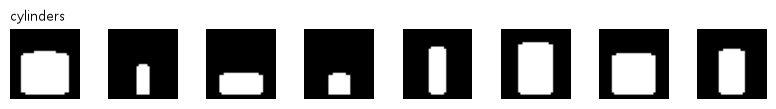

In [16]:
# ---------- 1-1 ----------
# 이미지 한 장은 '픽셀 수만큼의 숫자' (강의 23쪽의 480×360 예)
# 왜 · 이미지가 얼마나 큰 차원의 데이터인지 숫자로 실감하기 위해
print(f"480×360 흑백 사진 1장 = 숫자 {480 * 360:,}개")    # 가로 × 세로
print(f"같은 크기 컬러(RGB) = 숫자 {480 * 360 * 3:,}개")  # 칸마다 값 3개
print(f"MNIST 손글씨 28×28 = 숫자 {28 * 28}개")           # 오토인코더-1의 입력


# 차원의 저주 맛보기: 점 500개 사이 거리의 '가장 먼 / 가장 가까운' 비율
# 왜 · 차원이 커질수록 점 사이 거리가 비슷해지는 현상을 숫자로 보기 위해
rng = np.random.default_rng(0)                                      # 난수 고정
for d in [2, 10, 100, 1000]:                                        # 차원(축 수)을 늘리며
    P = rng.random((500, d))                                        # 0~1 사이 점 500개
    D = np.sqrt(((P[:100, None, :] - P[None, :, :]) ** 2).sum(-1))  # 앞 100개와 500개 사이 거리
    D = D[D > 0]                                                    # 자기 자신(0) 제외
    # 1에 가까울수록 다 비슷하게 멂
    print(f"{d:>4}차원 | 가장 먼 / 가장 가까운 = {D.max() / D.min():6.1f}")


# ---------- 1-2 ----------
# 원기둥 그림 만들기: 높이 h · 너비 w 두 숫자 → 32×32 그림 (강의 10 ~ 13쪽 예)
# 왜 · 숫자 두 개로 그림 전체가 정해지는 데이터를 만들어 압축의 뜻을 보이기 위해
def cylinder(h, w, size=32):                 # 높이 · 너비 → 그림
    yy, xx = np.mgrid[0:size, 0:size]        # 칸마다 (세로, 가로) 좌표
    dx = (xx - size / 2 + 0.5) / (w / 2)     # 가운데에서 떨어진 가로 거리 (너비 기준)
    bottom = size - 4                        # 바닥 위치
    top = bottom - h                         # 윗면 위치 = 바닥 - 높이
    body = (np.abs(dx) <= 1) & (yy >= top) & (yy <= bottom)  # 몸통 = 직사각형
    # 위 · 아래 타원
    caps = (dx ** 2 + ((yy - top) / 2) ** 2 <= 1) | (dx ** 2 + ((yy - bottom) / 2) ** 2 <= 1)
    return (body | caps).astype(np.float32)  # 원기둥 칸 = 1 · 바깥 = 0


# 숫자 2개가 그림 1,024칸을 정함
# 왜 · 많은 칸이 실제로는 적은 숫자로 설명된다는 것을 확인하기 위해
img = cylinder(12, 10)                                         # 높이 12 · 너비 10
print("그림 모양:", img.shape, "| 칸 수:", img.size, "| 칠해진 칸:", int(img.sum()))  # 32×32
taller = cylinder(16, 10)                                      # 높이만 +4
print("높이 +4 → 바뀐 칸:", int((img != taller).sum()), "개")  # 픽셀로 고치면 이만큼


# 데이터셋 2,000장: 높이 · 너비를 무작위로 (라벨은 확인용으로만 따로 보관)
# 왜 · 라벨 없이 학습할 데이터를 만들고 라벨은 확인용으로만 남기기 위해
rng = np.random.default_rng(0)                                  # 난수 고정
H = rng.uniform(6, 22, 2000)                                    # 높이 6 ~ 22칸
W = rng.uniform(6, 22, 2000)                                    # 너비 6 ~ 22칸
# (2000, 1, 32, 32)
X = torch.tensor(np.stack([cylinder(h, w) for h, w in zip(H, W)])).unsqueeze(1).to(device)
print("데이터:", tuple(X.shape), "| 값:", X.unique().tolist())  # 0과 1만
show([("cylinders", X)])                                        # 앞 8장

**실행 흐름**

1. 2-1 인코더 · 디코더
2. 2-2 파라미터 세기
3. 2-3 손실 = 입력과 출력의 차이

In [17]:
# ---------- 2-1 ----------
# 인코더 · 디코더 · 잠재 벡터 (강의 17 ~ 21쪽): 1,024 → 128 → 2 → 128 → 1,024
# 왜 · 강의의 구조를 그대로 코드로 옮겨 각 부분의 역할을 보기 위해
class AutoEncoder(nn.Module):          # nn.Module을 물려받은 모델
    def __init__(self, latent_dim=2):  # 잠재 크기를 인자로
        super().__init__()             # 부모 초기화
        self.encoder = nn.Sequential(  # 줄이는 쪽
            nn.Flatten(), nn.Linear(1024, 128), nn.ReLU(),
            nn.Linear(128, latent_dim))
        self.decoder = nn.Sequential(  # 되돌리는 쪽
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 1024), nn.Sigmoid())

    # 왜 · 입력 → 잠재 벡터 → 복원의 흐름을 한 메서드로 묶기 위해
    def forward(self, x):                              # model(x) 할 때 실행되는 길
        z = self.encoder(x)                            # 잠재 벡터
        return self.decoder(z).reshape(-1, 1, 32, 32)  # 1,024 → 그림 모양


# 한 장을 층마다 통과시키며 모양 찍기
# 왜 · 층을 지날 때 모양이 어떻게 줄었다 늘어나는지 확인하기 위해
torch.manual_seed(0)                                      # 같은 시작 가중치
ae = AutoEncoder(2).to(device)                            # 잠재 2 = 높이 · 너비 자리
h = X[:1]                                                 # 한 장 (1, 1, 32, 32)
print(f"{'입력':<10}", tuple(h.shape))                    # 출발 모양
for layer in list(ae.encoder) + list(ae.decoder):         # 인코더 → 디코더 층을 차례로
    h = layer(h)                                          # 층 하나 통과
    print(f"{type(layer).__name__:<10}", tuple(h.shape))  # 층 이름 + 나온 모양
print(f"{'reshape':<10}", tuple(ae(X[:1]).shape))         # forward 끝의 접기


# ---------- 2-2 ----------
# 강의 23쪽 그림의 층 크기로 파라미터 수 세기 (meta 장치 = 모양만 만들고 메모리는 안 씀)
# 왜 · 메모리를 쓰지 않고 큰 모델의 크기만 세어 보기 위해
sizes = [480 * 360, 1000, 500, 10, 500, 1000, 480 * 360]  # 입력 → 은닉 → 잠재 10 → 은닉 → 출력
big = nn.Sequential(*[nn.Linear(a, b, device="meta") for a, b in zip(sizes, sizes[1:])])  # 층 6개
for layer in big:                                         # 층마다
    n = sum(p.numel() for p in layer.parameters())        # 가중치 + 편향 개수
    print(f"{layer.in_features:>7,} → {layer.out_features:>7,} | 파라미터 {n:>11,}")  # 층별
total = sum(p.numel() for p in big.parameters())          # 전체
print(f"전체 {total:,}개 | float32로 약 {total * 4 / 1024 ** 3:.2f} GB")  # 4바이트씩


# 이 노트북의 작은 원기둥 오토인코더와 비교
# 왜 · 실습 모델이 강의 모델보다 얼마나 작은지 비교하기 위해
small = sum(p.numel() for p in ae.parameters())            # 2-1 모델
print(f"원기둥 AE(1,024 → 128 → 2) 파라미터 {small:,}개")  # 훨씬 작음


# ---------- 2-3 ----------
# 학습 전 모델의 출력과 입력 비교 (강의 25 · 26쪽: 손실 = 입력과 출력의 차이)
# 왜 · 손실이 입력과 출력의 차이라는 것을 학습 전 결과로 먼저 보기 위해
x = X[:8]                                                            # 8장
with torch.no_grad():                                                # 기울기 계산 끔 (보기만)
    out = ae(x)                                                      # 학습 전 복원
by_hand = ((out - x) ** 2).mean().item()                             # 칸마다 (차이)² → 평균
print(f"직접 계산 MSE {by_hand:.4f} | F.mse_loss {F.mse_loss(out, x).item():.4f}")  # 같은 값
print(f"출력 범위 {out.min().item():.2f} ~ {out.max().item():.2f}")  # Sigmoid → 0~1 사이


# 정답 자리에는 입력 자신 → 라벨(H · W)은 손실에 들어가지 않음
# 왜 · 오토인코더는 라벨 없이 입력 자신을 정답으로 쓴다는 것을 확인하기 위해
# 출력 ↔ 입력
print("손실에 쓰는 것:", tuple(out.shape), "vs", tuple(x.shape), "(같은 모양 · 같은 그림)")

입력         (1, 1, 32, 32)
Flatten    (1, 1024)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 2)
Linear     (1, 128)
ReLU       (1, 128)
Linear     (1, 1024)
Sigmoid    (1, 1024)
reshape    (1, 1, 32, 32)
172,800 →   1,000 | 파라미터 172,801,000
  1,000 →     500 | 파라미터     500,500
    500 →      10 | 파라미터       5,010
     10 →     500 | 파라미터       5,500
    500 →   1,000 | 파라미터     501,000
  1,000 → 172,800 | 파라미터 172,972,800
전체 346,785,810개 | float32로 약 1.29 GB
원기둥 AE(1,024 → 128 → 2) 파라미터 263,938개
직접 계산 MSE 0.2508 | F.mse_loss 0.2508
출력 범위 0.36 ~ 0.63
손실에 쓰는 것: (8, 1, 32, 32) vs (8, 1, 32, 32) (같은 모양 · 같은 그림)


**실행 흐름**

1. 3-1 학습 전 · 후
2. 3-2 잠재 공간 읽기
3. 3-3 높이 방향 찾기

  epoch  1  loss 0.0532


  epoch 15  loss 0.0191


  epoch 30  loss 0.0103
복원 MSE  학습 전 0.2509 → 학습 후 0.0122


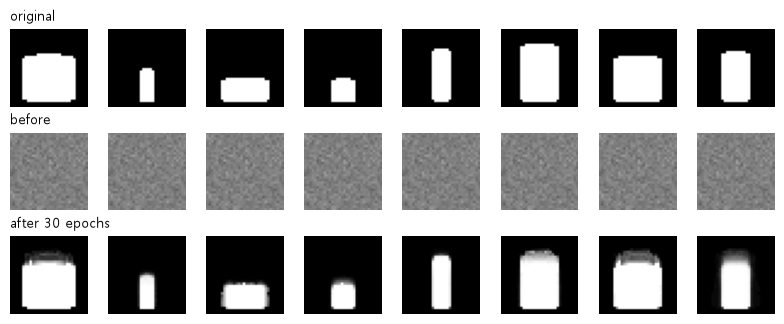

잠재 좌표 모양: (2000, 2)
높이  R² 0.649 | 축1 상관 +0.67 | 축2 상관 +0.42
너비  R² 0.800 | 축1 상관 -0.40 | 축2 상관 +0.82


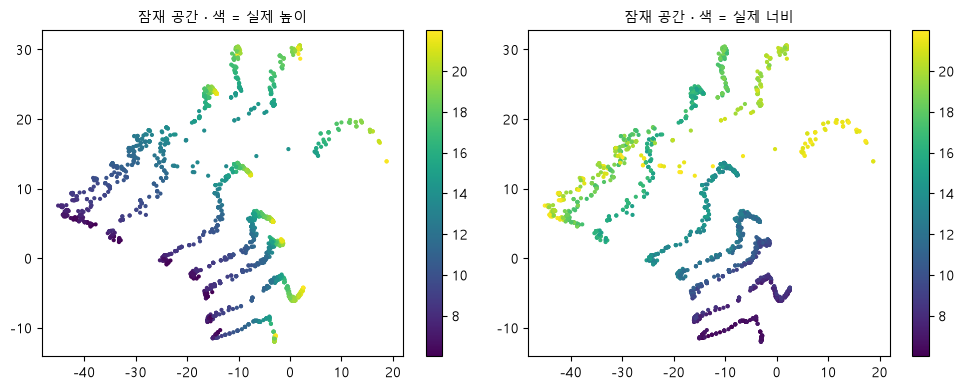

In [18]:
# ---------- 3-1 ----------
# 학습 함수 (강의 26쪽 1 → 2 → 3단계를 묶음마다 반복)
# 왜 · 강의의 학습 3단계를 그대로 함수로 만들어 여러 실험에 다시 쓰기 위해
def train(model, data, epochs=30, target=None, seed=0):               # 학습 후 모델을 돌려줌
    torch.manual_seed(seed)                                           # 섞는 순서 고정
    target = data if target is None else target                       # 정답: 따로 안 주면 입력 자신
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)               # 인코더 · 디코더 가중치 전부
    for epoch in range(epochs):                                       # 전체를 epochs번
        perm = torch.randperm(len(data), device=device)               # 번호 섞기
        for i in range(0, len(data), 64):                             # 64장씩
            b = perm[i:i + 64]                                        # 이번 묶음 번호
            opt.zero_grad()                                           # 앞 묶음 기울기 비우기
            loss = F.mse_loss(model(data[b]), target[b])              # ① x → z ② z → x̂ ③ 차이
            loss.backward()                                           # 기울기 계산
            opt.step()                                                # 가중치 갱신
        if epoch in (0, epochs // 2 - 1, epochs - 1):                 # 1 · 중간 · 끝만
            print(f"  epoch {epoch + 1:>2}  loss {loss.item():.4f}")  # 마지막 묶음 loss
    return model.eval()                                               # 평가 모드로 돌려줌


# 같은 출발점에서 학습 전 · 후 비교
# 왜 · 같은 seed에서 시작해 학습 효과만 비교하기 위해
torch.manual_seed(0)                                                           # 2-1과 같은 출발점
ae2 = train(AutoEncoder(2).to(device), X)                                      # 잠재 2 · 30 epoch
with torch.no_grad():                                                          # 보기만
    before, after = F.mse_loss(ae(X), X).item(), F.mse_loss(ae2(X), X).item()  # 2,000장 전체
print(f"복원 MSE  학습 전 {before:.4f} → 학습 후 {after:.4f}")  # 같은 데이터 · 같은 계산
with torch.no_grad():                                                          # 보기만
    show([("original", X), ("before", ae(X)), ("after 30 epochs", ae2(X))])    # 3줄


# ---------- 3-2 ----------
# 2,000장을 인코더에만 통과 → 잠재 좌표 (2000, 2)
# 왜 · 학습된 잠재 공간에 그림들이 어떻게 놓였는지 보기 위해
with torch.no_grad():                 # 꺼내기만
    Z = ae2.encoder(X).cpu().numpy()  # 한 장 = 점 하나
print("잠재 좌표 모양:", Z.shape)     # (장 수, 2)


# 잠재 두 축으로 진짜 높이 · 너비를 얼마나 맞힐 수 있나 (직선 맞춤의 R²)
# 왜 · 잠재 공간이 높이 · 너비 정보를 담았는지 숫자로 확인하기 위해
A = np.c_[Z, np.ones(len(Z))]                                           # [z1, z2, 1]
for name, t in [("높이", H), ("너비", W)]:                              # 확인용 라벨 두 개
    coef, *_ = np.linalg.lstsq(A, t, rcond=None)                        # z로 t를 맞추는 직선
    r2 = 1 - ((A @ coef - t) ** 2).sum() / ((t - t.mean()) ** 2).sum()  # 1에 가까울수록 잘 맞음
    print(f"{name}  R² {r2:.3f} | 축1 상관 {np.corrcoef(Z[:, 0], t)[0, 1]:+.2f}"  # R² · 축별 상관
          f" | 축2 상관 {np.corrcoef(Z[:, 1], t)[0, 1]:+.2f}")


# 같은 점에 높이 · 너비로 색만 입혀 보기 (라벨은 학습 뒤 색칠에만)
# 왜 · 라벨은 학습 뒤 색칠에만 써서 잠재 공간의 구조를 눈으로 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(10, 4))                  # 왼쪽 높이 · 오른쪽 너비
for ax, (name, t) in zip(axes, [("높이", H), ("너비", W)]):      # 두 그림
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=t, s=4, cmap="viridis")  # 잠재 평면의 점
    ax.set_title(f"잠재 공간 · 색 = 실제 {name}", fontsize=10)   # 어떤 색칠인지
    plt.colorbar(sc, ax=ax)                                      # 색 ↔ 값
plt.tight_layout()                                               # 간격 정리
plt.show()                                                       # 그림 출력


# ---------- 3-3 ----------
# 잠재 공간에서 '높이 방향'을 찾기: z ≈ (높이, 너비)를 직선으로 옮긴 것
# 왜 · 잠재 공간에서 뜻이 있는 방향을 찾아 새 그림을 만들기 위해
G = np.c_[H, W, np.ones(len(H))]           # [높이, 너비, 1]
M, *_ = np.linalg.lstsq(G, Z, rcond=None)  # (높이, 너비) → z 직선 맞춤
height_dir = M[0]                          # 높이 1칸당 z가 움직이는 방향

**실행 흐름**

1. z에 높이 방향을 더해 디코더로 새 그림 그리기

고른 원기둥: 높이 6.3 · 너비 10.5
잠재 +6 그림 ↔ 실제 높이+6  MSE 0.0108
원래 복원   ↔ 실제 높이+6  MSE 0.0418


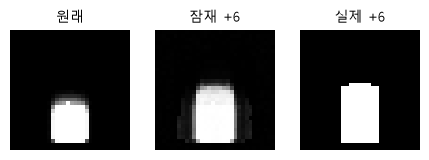

In [19]:
# 한 원기둥의 z에 '높이 +6'만큼 더해 디코더로 그리기 (강의 13쪽)
# 왜 · 잠재 벡터를 바꾸면 그림이 뜻대로 바뀌는지 확인하기 위해
k = 3                                                                            # 고를 원기둥 번호
z_new = torch.tensor(Z[k] + 6 * height_dir, dtype=torch.float32, device=device)  # 잠재에서 더하기
with torch.no_grad():                                                            # 그리기만
    made = ae2.decoder(z_new[None]).reshape(1, 1, 32, 32)                        # 새 그림
    same = ae2.decoder(torch.tensor(Z[k:k + 1], device=device)).reshape(1, 1, 32, 32)  # 원래 z 복원
truth = torch.tensor(cylinder(H[k] + 6, W[k]), device=device)[None, None]  # 실제 높이 +6 원기둥
print(f"고른 원기둥: 높이 {H[k]:.1f} · 너비 {W[k]:.1f}")                         # 출발점
print(f"잠재 +6 그림 ↔ 실제 높이+6  MSE {F.mse_loss(made, truth).item():.4f}")   # 가까울수록 작음
print(f"원래 복원   ↔ 실제 높이+6  MSE {F.mse_loss(same, truth).item():.4f}")    # 비교 기준
fig, axes = plt.subplots(1, 3, figsize=(4.5, 1.6))  # 원래 · 잠재 +6 · 실제
for ax, (name, im) in zip(axes, [("원래", same), ("잠재 +6", made), ("실제 +6", truth)]):  # 세 장
    ax.imshow(im[0, 0].cpu(), cmap="gray", vmin=0, vmax=1)                       # 밝기 0~1
    ax.set_title(name, fontsize=10)                                              # 이름
    ax.axis("off")                                                               # 눈금 숨김
plt.tight_layout()                                                               # 간격 정리
plt.show()                                                                       # 그림 출력

**실행 흐름**

1. 4-1 노이즈 제거
2. 4-2 복원 오차로 이상 찾기

  epoch  1  loss 0.0595


  epoch 15  loss 0.0144


  epoch 30  loss 0.0075
노이즈 그대로     MSE 0.0450
일반 AE(3-1)  → MSE 0.0546
노이즈 제거 AE → MSE 0.0062


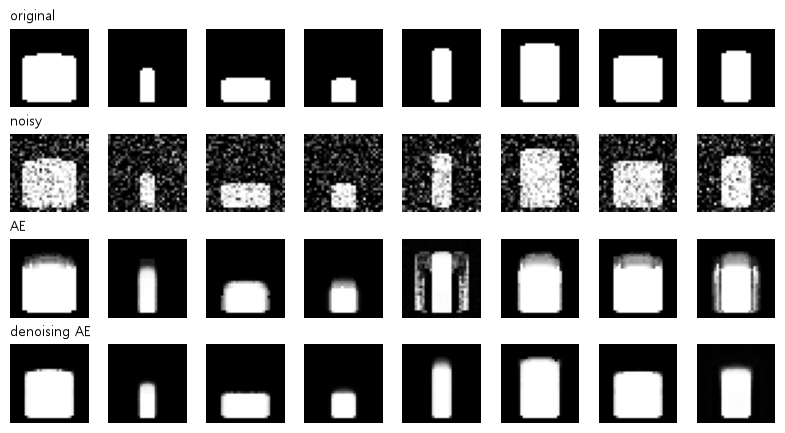

원기둥 200장 복원 오차 중앙값 0.0086
세모   200장 복원 오차 중앙값 0.0398
임곗값 0.0231 | 원기둥을 이상으로 본 비율 10% | 세모를 이상으로 잡은 비율 94%


In [20]:
# ---------- 4-1 ----------
# 노이즈 제거 (강의 28 · 29쪽): 입력은 노이즈 낀 그림, 정답은 깨끗한 그림
# 왜 · 입력만 망가뜨리고 정답은 깨끗하게 두어 노이즈 제거를 학습시키기 위해
g = torch.Generator().manual_seed(1)                  # 노이즈 고정
Xn = (X + 0.3 * torch.randn(tuple(X.shape), generator=g).to(device)).clamp(0, 1)  # 세기 0.3
torch.manual_seed(0)                                  # 같은 출발점
dae = train(AutoEncoder(2).to(device), Xn, target=X)  # 정답 자리에 깨끗한 X


# 같은 노이즈 그림을 두 모델에 넣어 비교
# 왜 · 보통 모델과 노이즈 제거 모델의 차이를 같은 입력으로 비교하기 위해
with torch.no_grad():                                                   # 보기만
    print(f"노이즈 그대로     MSE {F.mse_loss(Xn, X).item():.4f}")      # 아무것도 안 했을 때
    print(f"일반 AE(3-1)  → MSE {F.mse_loss(ae2(Xn), X).item():.4f}")   # 깨끗한 그림만 배운 모델
    print(f"노이즈 제거 AE → MSE {F.mse_loss(dae(Xn), X).item():.4f}")  # 노이즈 → 깨끗을 배운 모델
    show([("original", X), ("noisy", Xn), ("AE", ae2(Xn)), ("denoising AE", dae(Xn))])  # 4줄


# ---------- 4-2 ----------
# 원기둥만 배운 모델에 '처음 보는 모양'(세모)을 넣으면? (강의 15쪽: 이상 탐지에 활용)
# 왜 · 복원 오차로 처음 보는 데이터를 찾아내는 원리를 보이기 위해
def triangle(h, w, size=32):              # 처음 보는 모양 (세모)
    yy, xx = np.mgrid[0:size, 0:size]     # 칸마다 좌표
    bottom, top = size - 4, size - 4 - h  # 바닥 · 꼭대기
    half = (yy - top) / h * w / 2         # 내려갈수록 넓어지는 반폭
    inside = (yy >= top) & (yy <= bottom) & (np.abs(xx - size / 2 + 0.5) <= half)  # 세모 안
    return inside.astype(np.float32)      # 세모 = 1


# 왜 · 학습과 다른 seed로 처음 보는 세모 그림을 만들기 위해
rng2 = np.random.default_rng(1)                                             # 난수 고정
tri = np.stack([triangle(h, w) for h, w in rng2.uniform(8, 22, (200, 2))])  # 세모 200장
T = torch.tensor(tri).unsqueeze(1).to(device)                               # (200, 1, 32, 32)
with torch.no_grad():                                                       # 보기만
    err_c = ((ae2(X[:200]) - X[:200]) ** 2).flatten(1).mean(1)              # 원기둥 한 장마다 오차
    err_t = ((ae2(T) - T) ** 2).flatten(1).mean(1)                          # 세모 한 장마다 오차
print(f"원기둥 200장 복원 오차 중앙값 {err_c.median().item():.4f}")         # 배운 모양
print(f"세모   200장 복원 오차 중앙값 {err_t.median().item():.4f}")         # 처음 보는 모양
th = err_c.quantile(0.9).item()  # 원기둥 오차의 90% 지점 = 임곗값
# 잘못된 경보
print(f"임곗값 {th:.4f} | 원기둥을 이상으로 본 비율 {(err_c > th).float().mean().item():.0%}"
      f" | 세모를 이상으로 잡은 비율 {(err_t > th).float().mean().item():.0%}")

**실행 흐름**

1. 잠재 크기 1 · 2 · 8 학습
2. 복원 오차 · R² 비교
3. 복원 그림 비교

잠재 1 학습
  epoch  1  loss 0.0579


  epoch 15  loss 0.0350


  epoch 30  loss 0.0469
잠재 8 학습
  epoch  1  loss 0.0558


  epoch 15  loss 0.0043


  epoch 30  loss 0.0068
잠재 1 | 복원 MSE 0.0432 | 높이 R² 0.212 | 너비 R² 0.426
잠재 2 | 복원 MSE 0.0122 | 높이 R² 0.649 | 너비 R² 0.800
잠재 8 | 복원 MSE 0.0061 | 높이 R² 0.975 | 너비 R² 0.968


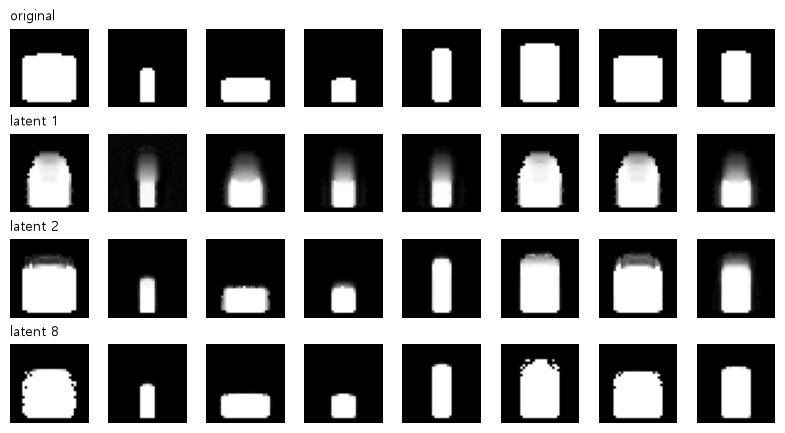

In [21]:
# ---------- 5. 종합 실습 ----------
# 1단계: 잠재 크기 1 · 2 · 8로 같은 조건 학습 (2는 3-1 모델 그대로)
# 왜 · 잠재 크기만 바꿔 공정하게 비교하기 위해
models = {2: ae2}                                    # 잠재 크기 → 모델
for d in [1, 8]:                                     # 새로 학습할 크기
    print(f"잠재 {d} 학습")                          # 어느 모델의 loss인지
    torch.manual_seed(0)                             # 같은 출발점
    models[d] = train(AutoEncoder(d).to(device), X)  # 30 epoch


# 2단계: 복원 오차 · 높이와 너비를 얼마나 담았나 (R²)
# 왜 · 잠재 크기에 따라 복원 품질과 담긴 정보가 어떻게 바뀌는지 재기 위해
def r2_of(model):                                   # 잠재로 높이 · 너비를 맞힌 정도
    with torch.no_grad():                           # 꺼내기만
        z = model.encoder(X).cpu().numpy()          # 잠재 좌표
    A_ = np.c_[z, np.ones(len(z))]                  # 직선 맞춤 재료
    out = []                                        # (높이 R², 너비 R²)
    for t in (H, W):                                # 두 요인
        c, *_ = np.linalg.lstsq(A_, t, rcond=None)  # 맞춤
        out.append(1 - ((A_ @ c - t) ** 2).sum() / ((t - t.mean()) ** 2).sum())  # R²
    return out                                      # (높이 R², 너비 R²)


# 왜 · 잠재 크기마다 같은 방법으로 결과를 모으기 위해
for d in [1, 2, 8]:                                                              # 크기 순서로
    with torch.no_grad():                                                        # 보기만
        m = F.mse_loss(models[d](X), X).item()                                   # 2,000장 복원 오차
    rh, rw = r2_of(models[d])                                                    # 두 요인 R²
    print(f"잠재 {d} | 복원 MSE {m:.4f} | 높이 R² {rh:.3f} | 너비 R² {rw:.3f}")  # 한 줄 비교


# 3단계: 같은 8장을 세 모델로 복원해 나란히
# 왜 · 세 모델의 복원 결과를 같은 그림으로 비교하기 위해
with torch.no_grad():                                                             # 그리기만
    show([("original", X)] + [(f"latent {d}", models[d](X)) for d in [1, 2, 8]])  # 원본 + 3줄